# 02 – Futuros y cobertura
**Lab #2 – Derivados Financieros** · Puntos 6 a 12 (derivados/cobertura)

> **Ojo: este notebook todavía es la versión 1** (CSCO, ADI, PYPL, portafolio de máximo Sharpe, β mensual 0,8206). Se rehace punto por punto después de cerrar `01_portafolio` v2.
> Lo que cambia: acciones CSCO, ADI y AMGN; portafolio GMV (CSCO 36,71 %, ADI 19,37 %, AMGN 43,92 %); todo en mensual; β del portafolio nueva (≈ 0,54, sale del punto 5); MBG mensual con extremos razonables; trayectoria del peor escenario sin cobertura frente al portafolio cubierto.

## Configuración

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RAIZ = Path("..").resolve()              # raíz del repositorio (el notebook corre desde notebooks/)
if str(RAIZ) not in sys.path:
    sys.path.append(str(RAIZ))           # permite importar el paquete src/ (src/futuros.py)

from src.futuros import NQ               # especificaciones del contrato NQ (fuente: CME Group)

PROC = RAIZ / "data" / "processed"

## Punto 6 – Número óptimo de contratos (R8 – 7 %)

$$N^* = \frac{\beta_p \cdot V_p}{F_0 \cdot Q_F}$$

| Insumo | Valor | Fuente |
|---|---|---|
| $\beta_p$ | 0,8206 (β **mensual** del portafolio Máx. Sharpe) | Punto 5 |
| $V_p$ | USD 35.000.000 | Enunciado |
| $F_0$ | 28.534,00 (settle del NQZ6 al 30/10/2026) | CME Group – Settlements |
| $Q_F$ | USD 20 por punto del índice | CME Group – Contract Specs (detalle en el Punto 7) |

**β mensual:** Decidimos utilizar la $\beta$ mensual, ya que, las liquidaciones de la cuenta de margen son mensuales (agrupadas por trimestre), y en el punto 4 la exposición a cubrir la definimos como β mensual × $V_0$ ≈ USD 28,72 M. Decidimos mantener la coherencia entre VaR, betas y número de contratos. La $\beta$ diaria la reportamos como referencia.

**Redondeo (discretización):** los contratos son enteros y se redondean **hacia abajo** por lo siguiente:
1. 50.33 está mucho más cerca de 50 que de 51, así que el error es un poco más mínimo que subirlo a 51.
2. Para nuestro caso de la inversión el objetivo es **cubrir, no especular**.

In [2]:
# Punto 6: número óptimo de contratos
Vp = 35_000_000                                   # valor del portafolio (USD)
F0 = NQ["F0"]                                     # settle del NQZ6 al 30/10/2026
betas = {"mensual (elegida)": 0.8206,             # β mensual del portafolio (Punto 5)
         "diaria (referencia)": 0.9304}           # β diaria, solo para comparar

expo_contrato = F0 * NQ["Q_F"]                    # USD que representa un contrato (F0 × Q_F)

for nombre, b in betas.items():
    n_opt = b * Vp / expo_contrato                # N* = βp·Vp / (F0·Q_F)
    print(f"β {nombre}: βp·Vp = {b*Vp:,.0f} USD -> N* = {n_opt:.4f}")

beta_p = betas["mensual (elegida)"]               # beta usada en el resto del laboratorio
N_star = beta_p * Vp / expo_contrato              # número óptimo sin redondear
N      = int(np.floor(N_star))                    # redondeo hacia abajo: cubrir, no especular
razon_cob = N / N_star                            # % de la exposición beta efectivamente cubierta

print(f"\nN* = {N_star:.4f} -> N = {N} contratos CORTOS | razón de cobertura = {razon_cob:.2%}")
print(f"Exposición cubierta = {N*expo_contrato:,.2f} USD | sin cubrir = {beta_p*Vp - N*expo_contrato:,.2f} USD")

β mensual (elegida): βp·Vp = 28,721,000 USD -> N* = 50.3277
β diaria (referencia): βp·Vp = 32,564,000 USD -> N* = 57.0618

N* = 50.3277 -> N = 50 contratos CORTOS | razón de cobertura = 99.35%
Exposición cubierta = 28,534,000.00 USD | sin cubrir = 187,000.00 USD


## Punto 7 – Especificaciones del contrato y posición en futuros (R7 – 6 % · R9 – 10 %)

### 7.1 Especificaciones del contrato

**Plataforma:** CME Group (CME Globex). **Fecha de consulta:** 05/11/2026. Fuentes: [Contract Specs](https://www.cmegroup.com/markets/equities/nasdaq/e-mini-nasdaq-100.contractSpecs.html), [Margins](https://www.cmegroup.com/markets/equities/nasdaq/e-mini-nasdaq-100.margins.html), [Settlements](https://www.cmegroup.com/markets/equities/nasdaq/e-mini-nasdaq-100.settlements.html) y [ficha del contrato (PDF)](https://www.cmegroup.com/trading/equity-index/files/emini-nasdaq-100-futures-options.pdf). Capturas en `docs/referencias/`.

**Elección NQ vs. MNQ:** Para nuestro portafolio que se asemeja a la inversión institucional en este caso USD 35 M decidimos usar el E-mini NQ. Requiere 10 veces menos contratos que el Micro MNQ. Nos decidimos por el NQ, ya que, al requerir menos contrato minimizamos los costos de las comisiones en los 16 roll-overs y además investigando un poco más a fondo nos encontramos con que es el contrato más líquido del Nasdaq-100.

**Mark-to-market:** CME liquida diariamente, pero, el laboratorio supone **liquidación mensual**.

In [3]:
# ---- 7.1 Ficha del contrato (R7) ----
ficha = pd.DataFrame({
    "Especificación": ["Contrato", "Subyacente", "Tamaño (Q_F)", "Tick mínimo", "Valor del tick",
                       "Precio inicial F0 (30/10/2026)", "Vencimientos", "Vencimiento NQZ6",
                       "Liquidación al vencimiento", "Margen de mantenimiento (corto)",
                       "Margen inicial (supuesto)", "Plataforma"],
    "Valor": [NQ["codigo"], NQ["subyacente"], f"USD {NQ['Q_F']} × índice", f"{NQ['tick']} puntos",
              f"USD {NQ['valor_tick']:,.2f} por contrato", f"{NQ['F0']:,.2f}", NQ["vencimientos"],
              NQ["vencimiento"], NQ["liquidacion"], f"USD {NQ['margen_mant']:,.0f} por contrato",
              f"USD {NQ['margen_ini']:,.2f} por contrato (1,10 × VGM)", NQ["plataforma"]],
})
ficha

,Especificación,Valor
0,Contrato,NQZ6
1,Subyacente,Nasdaq-100 (^NDX)
2,Tamaño (Q_F),USD 20 × índice
3,Tick mínimo,0.25 puntos
4,Valor del tick,USD 5.00 por contrato
5,Precio inicial F0 (30/10/2026),"28,534.00"
6,Vencimientos,"mar, jun, sep, dic (tercer viernes)"
7,Vencimiento NQZ6,2026-12-18
8,Liquidación al vencimiento,en efectivo
9,Margen de mantenimiento (corto),"USD 39,407 por contrato"


### 7.2 Márgenes: supuesto del margen inicial

**CME** La página de márgenes de CME solo muestra el **MM** por contrato (USD 39.407 para el NQZ6 en posición corta). El margen inicial se obtiene de la regla del marco establecida por la propia página **CME SPAN 2** ([PDF](https://www.cmegroup.com/clearing/files/cme-span-2-margin-framework.pdf), diapositiva *"Margin Result Breakdown (Continued)"*):

| Tipo de cuenta | Margen inicial |
|---|---|
| Especulativa | $VGI_0 = 1{.}1 \times VGM$ |
| Cobertura (hedge) o miembro | $VGI_0 = VGM$ |

**Supuesto adoptado:** $VGI_0 = 1{.}10 \times VGM =$ **USD 43,347.70 por contrato** Aunque en nuestra inversión adoptemos la entidad de un hedger. Las razones por la que decidimos utilizar este **MI** son:

1. **Coherencia con la notación de clases** (Clase 18: $VGM = VGI_0 \times \%$). Aquí el porcentaje es $1/1{.}10 = 90{.}9\,\%$. Con la regla del hedger que nos ofrece CME no tendríamos alguna pequeña oportunidad a equivocarnos, ya que, los niveles de **MI** y **MM** seían los mismos y cualquier pérdida generaría un llamado al margen.
2. **Fuente oficiales de decisión:** en lugar de tomar un porcentaje arbitrario como lo es el excel de referencia para realizar este ejercicio un 0.5% del ejemplo sería irreal para el NQ.

**MM fijo en USD durante los 4 años** CME publica un margen distinto por vencimiento, en la ruta hay una screenshot `docs/referencias/cme_nq_margins_consulta_2026-11-05.png`, esta tabla es una foto al día de consulta que CME ajusta. Por eso se decidimos mantener el valor del NQZ6 en todos los roll-overs.

**Coherencia temporal** Los márgenes se consultaron el 05/11/2026. Entre el 29/10/2026 y el 05/11/2026 CME no emitió avisos de márgenes de *Equity* los avisos que existen dentro de ese rango de tiempo cubren otras clases de activo así que el valor consultado es el vigente al 30/10/2026.

**Cuenta de margen clases:** En nuestros apuntes en especial la clase 18, si el saldo cae por debajo de $VGM$, hay llamado al margen y se repone **hasta $VGI_0$**.

In [4]:
# 7.2 Márgenes y posición en futuros
VGM_c  = NQ["margen_mant"]                        # VGM por contrato (CME, columna corta)
VGI0_c = NQ["margen_ini"]                         # VGI0 por contrato = 1.10 × VGM (CME SPAN 2)

expo_total = N * expo_contrato                    # exposición total = N × Q_F × F0
VGI0 = N * VGI0_c                                 # garantía inicial total a depositar
VGM  = N * VGM_c                                  # margen de mantenimiento total
apalancamiento = expo_total / VGI0                # veces que la exposición supera la garantía

valor_tick_pos = N * NQ["valor_tick"]             # USD que gana o pierde la posición por tick
holgura_ticks  = (VGI0 - VGM) / valor_tick_pos    # ticks en contra antes de un llamado al margen
holgura_pct    = holgura_ticks * NQ["tick"] / F0  # esa holgura como % del precio del futuro

posicion = pd.Series({
    "beta_p (mensual)": beta_p, "N*": N_star, "N (contratos cortos)": N, "Razón de cobertura": razon_cob,
    "Exposición por contrato (USD)": expo_contrato, "Exposición cubierta (USD)": expo_total,
    "VGI0 por contrato (USD)": VGI0_c, "VGM por contrato (USD)": VGM_c,
    "VGI0 total (USD)": VGI0, "VGM total (USD)": VGM, "Apalancamiento (veces)": apalancamiento,
    "Valor tick posición (USD)": valor_tick_pos, "Holgura (ticks)": holgura_ticks, "Holgura (% de F0)": holgura_pct,
})
posicion.to_csv(PROC / "posicion_futuros.csv", header=["valor"])   # insumo de los Puntos 8 a 12
posicion.to_frame("valor").style.format("{:,.4f}")

,valor
beta_p (mensual),0.8206
N*,50.3277
N (contratos cortos),50.0000
Razón de cobertura,0.9935
Exposición por contrato (USD),"570,680.0000"
Exposición cubierta (USD),"28,534,000.0000"
VGI0 por contrato (USD),"43,347.7000"
VGM por contrato (USD),"39,407.0000"
VGI0 total (USD),"2,167,385.0000"
VGM total (USD),"1,970,350.0000"


**Interpretación:** Con una garantía inicial de unos USD 2.17 M se cubren unos USD 28.5 M de exposición al Nasdaq-100. El rango entre $VGI_0$ y $VGM$ es bastante estrecho, apróximadamente 0.69% del precio y como la posición es **corta**, cualquier mes en que el futuro suba más que ese pequeño porcentaje generará un llamado al margen.

### 7.3 Posición corta vs. larga con ticks (R9)

**Posición corta vs larga:** La posición de la cobertura depende a que dirección estemos apuntanod y de qué riesgo se quiere neutralizar:

| | **Corto en futuros** (vender) | **Largo en futuros** (comprar) |
|---|---|---|
| Perfil | Quien ya posee el activo y teme que su precio **baje** | Quien va a comprar el activo en el futuro y teme que su precio **suba** |
| Relación con el laboratorio | Nuestra entidad ya tiene USD 35 M invertidos en CSCO, ADI y PYPL | Un fondo que recibirá recursos en 3 meses para invertir en acciones del Nasdaq-100 |
| Lógica de la cobertura | Lo que se pierde en las acciones se gana en el futuro | El mayor costo de compra se compensa con la ganancia del futuro |

Es la misma lógica del ejemplo que se vió en la Clase 19: como iba a **comprar** dólares y temía que subieran, tomó una posición **larga** y la ganancia en el futuro compensó el sobrecosto en el spot dando un resultado neto = 0. Nuestro caso es al contrario, nuestra entidad **ya posee** las acciones y queremos protegernos de una caída proveniente del mercado, por eso, la posición correcta es estar en **corto por 50 contratos NQZ6**.

**Qué riesgo cubrimos?** Solo el **riesgo sistemático**, es decir, la parte del movimiento del portafolio que se explica por el Nasdaq-100. El futuro sobre el índice que seguimos no cubre el **riesgo no sistemático**. En nuestro caso el riesgo sistemático se explica en el 56% de la varianza del portafolio ($R^2 = 0.56$) y el no sistemático representa el movimiento de las empresas siendo un 44%.

**Cálculo con ticks (Notactión de clase 19):**

$$\text{N.º de ticks} = \frac{\Delta F}{\text{tick}} \qquad \text{P\&G} = \text{N.º de ticks} \times \text{valor del tick} \times N$$

- tick = 0.25 puntos.
- valor del tick = USD 5 por contrato. 
- $N = 50$, es decir, **USD 250 por tick para toda la posición**. 

Para la posición corta se invierte el signo: el corto gana cuando el precio baja.

Para cada escenario el precio final del futuro se redondea al tick, además, se supone que el futuro se mueve en el mismo porcentaje que el índice y que el cambio del portafolio es $\beta_p \times \Delta\text{índice} \times V_p$.

In [5]:
# 7.3 Posición corta vs. larga: escenarios con ticks (R9)
movs = [-0.10, -0.05, 0.05, 0.10]                     # escenarios de variación del índice (y del futuro)
filas = []
for m in movs:
    F1    = np.round(F0 * (1 + m) / NQ["tick"]) * NQ["tick"]   # precio final redondeado al tick (Clase 19)
    dF    = F1 - F0                                     # variación del precio del futuro (puntos)
    ticks = dF / NQ["tick"]                             # n.º de ticks = ΔF / tick
    pg_largo = ticks * NQ["valor_tick"] * N             # P&G largo = ticks × valor del tick × N
    pg_corto = -pg_largo                                # el corto gana lo que el largo pierde
    dV = beta_p * m * Vp                                # cambio esperado del portafolio de acciones (β × Δ índice × Vp)
    filas.append({"Δ índice": m, "F final": F1, "ΔF (pts)": dF, "Ticks": ticks,
                  "P&G largo": pg_largo, "P&G corto": pg_corto, "Δ acciones": dV,
                  "Neto acciones + corto": dV + pg_corto, "Neto acciones + largo": dV + pg_largo})

escenarios = pd.DataFrame(filas)
escenarios.to_csv(PROC / "escenarios_ticks_R9.csv", index=False)
escenarios.style.format({"Δ índice": "{:+.0%}", "F final": "{:,.2f}", "ΔF (pts)": "{:+,.2f}",
                         "Ticks": "{:+,.0f}"} | {c: "{:+,.0f}" for c in escenarios.columns[4:]})

,Δ índice,F final,ΔF (pts),Ticks,P&G largo,P&G corto,Δ acciones,Neto acciones + corto,Neto acciones + largo
0,-10%,"25,680.50","-2,853.50","-11,414","-2,853,500","+2,853,500","-2,872,100","-18,600","-5,725,600"
1,-5%,"27,107.25","-1,426.75","-5,707","-1,426,750","+1,426,750","-1,436,050","-9,300","-2,862,800"
2,+5%,"29,960.75","+1,426.75","+5,707","+1,426,750","-1,426,750","+1,436,050","+9,300","+2,862,800"
3,+10%,"31,387.50","+2,853.50","+11,414","+2,853,500","-2,853,500","+2,872,100","+18,600","+5,725,600"


**Interpretación:**

- **Si el mercado baja (riesgo que queremos neutralizar):** Con una caída del 10%, el contrato de futuro baja 2,853.50 puntos (11,414 ticks). Las acciones pierden cerca de USD 2.87 M, pero la posición corta gana USD 2.85 M, así que la pérdida neta es de apenas **USD 18,600**. Esta perdrida corresponde a la pequeña parte del contrato que no cubrimos por el redondeo hacia abajo, esto no corresponde a que la cobertura esté mal ejecutada.

- **Si el mercado sube:** Con una subida del 10% las acciones ganan USD 2.87 M y la posición corta pierde USD 2.85 M. Además, como el rango entre $VGI_0$ y $VGM$ es de solo 0.69% del precio, esa pérdida se paga mes a mes con **margin call**. Inferimos directamente que este es el costo a pagar por la cobertura, donde se renuncia a la ganancia que puede haber en el alza a cambio de protegernos en la caída. Nosotros como inversionistas esperamos que las acciones suban, pero, tomamos el perfil de hedger y adquirimos contratos en corto para mitigar los escenarios en que el mercado se desplome.

- **Una posición en largo** sobre una cartera donde ya le estamos apostando al crecimiento no cubriría nada tener contratos en largo, mejor dicho, estaríamos **duplicando la exposición** al mercado. Con la misma caída del 10% la pérdida sería el doble, en este preciso instante ya no tendríamos perfil de hedger sino un perfil especulativo.

## Punto 8 – Simulación, flujos mensuales y cuenta de margen por ticks (R10 – 12 %)

### 8.1 Qué precios usamos?

El Excel de referencia estima el portafolio con datos de 2016 a 2020 y después realiza la cuenta de margen con los precios **reales** del índice y del futuro desde el año 2021 a 2024, es decir, un periodo que ya había ocurrido. En nuestro caso el horizonte de eventos aún no ha ocurrido, por lo que, no tenemos precios reales para usa, por consiguiente, los generamos con el modelo **MBG**.

Replicamos la estructura del Excel: una columna para el precio del **índice** y otra para el precio del **futuro**, liquidación periódica, margen y margin call. La única diferencia entre ambos ejercicios es que nuestra ejecución es mensual (48 meses agrupados en 16 trimestres) y que la liquidación se calcula **por ticks**.

**Índice ^NDX (MBG mensual):**

$$S_{t} = S_{t-1}\, e^{(\mu - \frac{1}{2}\sigma^2)\Delta t + \sigma\sqrt{\Delta t}\,Z_t}, \qquad Z_t \sim N(0,1), \quad \Delta t = \tfrac{1}{12}$$

- $S_0$ = 28,384.85, cierre del ^NDX el 30/10/2026 (`data/raw/close_diario.csv`).
- $(\mu - \frac{1}{2}\sigma^2)\Delta t$ = media de los retornos log mensuales y $\sigma\sqrt{\Delta t}$ = su desviación estándar (120 meses), ambos componentes del índice ^NDX.

**Precio del futuro (costo de llevar):**

$$F_t = S_t\, e^{c\,(T_k - t)}, \qquad c = \frac{\ln(F_0/S_0)}{T_0}$$

$c$ es el **costo de llevar implícito** del mercado. $T_k$ es el vencimiento del contrato que se tenga abierto. Los precios del futuro se redondean al tick (0.25).

**Qué contrato hay abierto cada mes?** El NQZ6 vence el 18/12/2026, antes de que termine el primer trimestre de nuestra inversión, para no manejar contratos vencidos, una opción acertada sería **manejar el siguiente vencimiento al cierre del mes anterior al vencimiento** (diciembre sería el de noviembre, marzo sería el de febrero, el de junio sería el de mayo y septiembre sería el de agosto). Se sigue renovando **cada 3 meses**, como se pide en el laboratorio.

**Trayectoria representativa:** se simulan 10,000 trayectorias y para la tabla mensual se toma la de **precio final mediano** del índice, es decir, el escenario "intermedio". Las 10,000 trayectorias se guardan para los puntos 10 y 11.

In [6]:
# 8.1 Simulación del índice (MBG) y del precio del futuro
close = pd.read_csv(RAIZ / "data" / "raw" / "close_diario.csv", index_col=0, parse_dates=True)
ret_m = pd.read_csv(PROC / "retornos_mensuales.csv", index_col=0, parse_dates=True)["^NDX"]

S0   = close.loc["2026-10-30", "^NDX"]             # cierre del ^NDX el 30/10/2026
drift_m = ret_m.mean()                              # (μ − σ²/2)·Δt : media de los retornos log mensuales
sigma_m = ret_m.std()                               # σ·√Δt : desviación de los retornos log mensuales
T0   = (pd.Timestamp("2026-12-18") - pd.Timestamp("2026-10-30")).days / 365   # plazo del NQZ6 (años)
c    = np.log(F0 / S0) / T0                         # costo de llevar implícito (≈ r − q)

print(f"S0 = {S0:,.2f} | F0 = {F0:,.2f} | base inicial b0 = S0 − F0 = {S0 - F0:,.2f}")
print(f"drift mensual = {drift_m:.4%} | σ mensual = {sigma_m:.4%} | σ anual = {sigma_m*np.sqrt(12):.2%}")
print(f"costo de llevar implícito c = {c:.4%} anual")

# Fechas: 30/10/2026 y los 48 cierres de mes siguientes (último: oct-2030)
fechas = pd.DatetimeIndex([pd.Timestamp("2026-10-30")]).append(
    pd.date_range("2026-11-30", periods=48, freq="BME"))

# Simulación de 10,000 trayectorias del índice (MBG)
n_sim, n_mes = 10_000, 48
rng = np.random.default_rng(20261030)              # semilla fija: resultados reproducibles
Z   = rng.standard_normal((n_mes, n_sim))           # choques N(0,1)
S_sim = S0 * np.exp(np.vstack([np.zeros(n_sim), np.cumsum(drift_m + sigma_m * Z, axis=0)]))
S_sim = pd.DataFrame(S_sim, index=fechas)          # filas = meses (0..48), columnas = trayectorias
S_sim.to_csv(PROC / "simulacion_ndx_10000.csv")    # insumo de los Puntos 10 y 11

# Trayectoria representativa: la del precio final mediano (escenario intermedio)
final = S_sim.iloc[-1]
k_med = (final - final.median()).abs().idxmin()
S = S_sim[k_med]
print(f"\nTrayectoria elegida: #{k_med} | S final = {S.iloc[-1]:,.2f} "
      f"(percentil 5 = {final.quantile(.05):,.0f} | mediana = {final.median():,.0f} | percentil 95 = {final.quantile(.95):,.0f})")

S0 = 28,384.85 | F0 = 28,534.00 | base inicial b0 = S0 − F0 = -149.15
drift mensual = 1.4808% | σ mensual = 5.4912% | σ anual = 19.02%
costo de llevar implícito c = 3.9039% anual

Trayectoria elegida: #849 | S final = 57,748.23 (percentil 5 = 31,125 | mediana = 57,750 | percentil 95 = 108,414)


In [7]:
# 8.1 Calendario de contratos y precio del futuro
def tercer_viernes(anio, mes):
    d = pd.Timestamp(anio, mes, 1)
    return d + pd.Timedelta(days=(4 - d.weekday()) % 7 + 14)   # primer viernes + 2 semanas

letra = {3: "H", 6: "M", 9: "U", 12: "Z"}                      # códigos de mes de CME
venc = [(f"NQ{letra[m]}{str(a)[-1]}", tercer_viernes(a, m))
        for a in range(2026, 2031) for m in (3, 6, 9, 12) if tercer_viernes(a, m) > fechas[0]]

def contrato_del_mes(fecha_fin):
    """Contrato abierto durante el mes que termina en fecha_fin: el primero que vence después de esa fecha."""
    return next((cod, v) for cod, v in venc if v > fecha_fin)

def precio_futuro(S_t, fecha, vencimiento):
    """F = S·e^{c(T−t)}, redondeado al tick."""
    F = S_t * np.exp(c * (vencimiento - fecha).days / 365)
    return np.round(F / NQ["tick"]) * NQ["tick"]

print("Calendario de vencimientos:", ", ".join(f"{k} ({v:%d/%m/%Y})" for k, v in venc[:6]), "…")

Calendario de vencimientos: NQZ6 (18/12/2026), NQH7 (19/03/2027), NQM7 (18/06/2027), NQU7 (17/09/2027), NQZ7 (17/12/2027), NQH8 (17/03/2028) …


In [8]:
# 8.2 Cuenta de margen mensual por ticks (posición corta, N = 50)
filas = []
saldo, mc_ant = VGI0, 0.0                           # el mes 0 arranca con la garantía inicial
for t in range(1, n_mes + 1):
    f_ini, f_fin = fechas[t - 1], fechas[t]
    cod, v = contrato_del_mes(f_fin)                # contrato abierto durante el mes
    F_ini = precio_futuro(S.iloc[t - 1], f_ini, v)  # precio del contrato al inicio del mes
    F_fin = precio_futuro(S.iloc[t], f_fin, v)      # precio del contrato al cierre del mes
    dF    = F_fin - F_ini                           # variación del precio (puntos)
    ticks = dF / NQ["tick"]                         # n.º de ticks = ΔF / tick
    pg_largo = ticks * NQ["valor_tick"] * N         # P&G largo = ticks × valor del tick × N
    pg_corto = -pg_largo                            # P&G corto (nuestra posición)
    saldo = saldo + mc_ant + pg_corto               # saldo = saldo anterior + reposición anterior + liquidación
    mc = VGI0 - saldo if saldo < VGM else 0.0       # margin call: se repone hasta VGI0 (Clase 18)
    filas.append({"Mes": t, "Trimestre": f"T{(t - 1) // 3 + 1}", "Fecha": f_fin.date(), "Contrato": cod,
                  "S índice": S.iloc[t], "F inicial": F_ini, "F final": F_fin, "ΔF": dF, "Ticks": ticks,
                  "P&G largo": pg_largo, "P&G corto": pg_corto, "Saldo margen": saldo,
                  "Margin call": saldo < VGM, "Reposición": mc, "Rend índice": S.iloc[t] / S.iloc[t-1] - 1})
    mc_ant = mc

cuenta = pd.DataFrame(filas).set_index("Mes")
cuenta.to_csv(PROC / "cuenta_margen_mensual.csv")
pd.set_option("display.max_rows", 60)
cuenta.style.format({"S índice": "{:,.2f}", "F inicial": "{:,.2f}", "F final": "{:,.2f}", "ΔF": "{:+,.2f}",
                     "Ticks": "{:+,.0f}", "P&G largo": "{:+,.0f}", "P&G corto": "{:+,.0f}",
                     "Saldo margen": "{:,.0f}", "Reposición": "{:,.0f}", "Rend índice": "{:+.2%}"})

,Trimestre,Fecha,Contrato,S índice,F inicial,F final,ΔF,Ticks,P&G largo,P&G corto,Saldo margen,Margin call,Reposición,Rend índice
Mes,,,,,,,,,,,,,,
1,T1,2026-11-30,NQZ6,"28,332.04","28,534.00","28,386.75",-147.25,-589,"-147,250","+147,250","2,314,635",False,0,-0.19%
2,T1,2026-12-31,NQH7,"27,802.10","28,664.25","28,035.00",-629.25,"-2,517","-629,250","+629,250","2,943,885",False,0,-1.87%
3,T1,2027-01-29,NQH7,"27,899.80","28,035.00","28,046.50",+11.50,+46,"+11,500","-11,500","2,932,385",False,0,+0.35%
4,T2,2027-02-26,NQH7,"27,908.48","28,046.50","27,971.25",-75.25,-301,"-75,250","+75,250","3,007,635",False,0,+0.03%
5,T2,2027-03-31,NQM7,"27,566.74","28,244.75","27,800.75",-444.00,"-1,776","-444,000","+444,000","3,451,635",False,0,-1.22%
6,T2,2027-04-30,NQM7,"28,767.48","27,800.75","28,918.75","+1,118.00","+4,472","+1,118,000","-1,118,000","2,333,635",False,0,+4.36%
7,T3,2027-05-31,NQM7,"28,766.23","28,918.75","28,821.75",-97.00,-388,"-97,000","+97,000","2,430,635",False,0,-0.00%
8,T3,2027-06-30,NQU7,"28,495.10","29,103.50","28,737.00",-366.50,"-1,466","-366,500","+366,500","2,797,135",False,0,-0.94%
9,T3,2027-07-30,NQU7,"27,796.12","28,737.00","27,942.25",-794.75,"-3,179","-794,750","+794,750","3,591,885",False,0,-2.45%


In [9]:
# 8.3 Resumen por trimestre y totales
trim = cuenta.groupby("Trimestre", sort=False).agg(
    Contrato=("Contrato", "last"), S_final=("S índice", "last"), F_final=("F final", "last"),
    PG_largo=("P&G largo", "sum"), PG_corto=("P&G corto", "sum"),
    Margin_calls=("Margin call", "sum"), Reposicion=("Reposición", "sum"), Saldo_final=("Saldo margen", "last"))
trim.to_csv(PROC / "cuenta_margen_trimestral.csv")

PyG   = cuenta["P&G corto"].sum()                   # P&G acumulado de la posición corta
repos = cuenta["Reposición"].sum()                  # total repuesto por llamados al margen
print(f"P&G acumulado del corto = {PyG:,.0f} USD | rentabilidad sobre VGI0 = {PyG / VGI0:.2%}")
print(f"Llamados al margen: {int(cuenta['Margin call'].sum())} de {n_mes} meses | total repuesto = {repos:,.0f} USD")
print(f"Aporte total a la cuenta = VGI0 + reposiciones = {VGI0 + repos:,.0f} USD | saldo final = {cuenta['Saldo margen'].iloc[-1]:,.0f} USD")
trim.style.format({"S_final": "{:,.2f}", "F_final": "{:,.2f}", "PG_largo": "{:+,.0f}", "PG_corto": "{:+,.0f}",
                   "Reposicion": "{:,.0f}", "Saldo_final": "{:,.0f}"})

P&G acumulado del corto = -23,850,250 USD | rentabilidad sobre VGI0 = -1100.42%
Llamados al margen: 9 de 48 meses | total repuesto = 24,723,500 USD
Aporte total a la cuenta = VGI0 + reposiciones = 26,890,885 USD | saldo final = 3,040,635 USD


,Contrato,S_final,F_final,PG_largo,PG_corto,Margin_calls,Reposicion,Saldo_final
Trimestre,,,,,,,,
T1,NQH7,"27,899.80","28,046.50","-765,000","+765,000",0,0,"2,932,385"
T2,NQM7,"28,767.48","28,918.75","+598,750","-598,750",0,0,"2,333,635"
T3,NQU7,"27,796.12","27,942.25","-1,258,250","+1,258,250",0,0,"3,591,885"
T4,NQZ7,"30,097.62","30,255.75","+2,016,000","-2,016,000",1,"1,067,250","2,643,135"
T5,NQH8,"29,542.27","29,688.00","-868,750","+868,750",0,0,"3,511,885"
T6,NQM8,"31,184.94","31,348.75","+1,369,500","-1,369,500",0,0,"2,142,385"
T7,NQU8,"29,711.93","29,858.50","-1,779,000","+1,779,000",0,0,"3,921,385"
T8,NQZ8,"34,489.97","34,656.25","+4,489,750","-4,489,750",1,"2,938,250","2,369,885"
T9,NQH9,"34,160.68","34,321.75","-664,500","+664,500",0,0,"3,034,385"


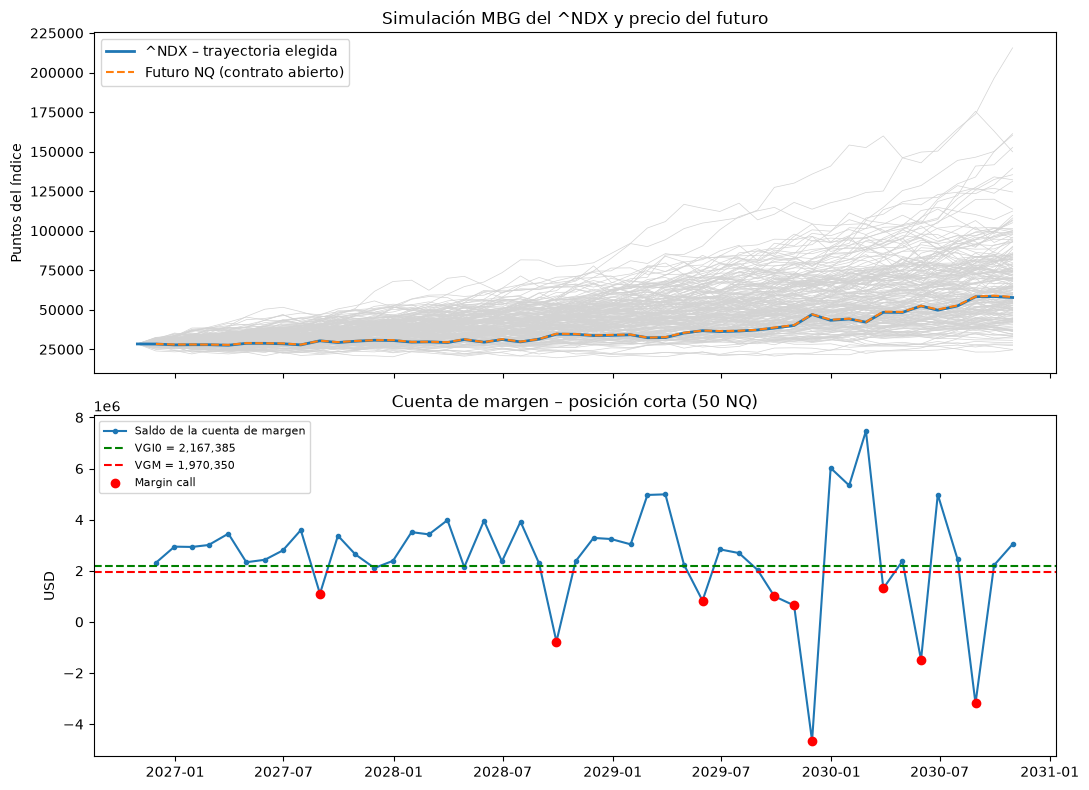

In [10]:
# 8.4 Gráfico: trayectoria simulada y cuenta de margen
fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
ax[0].plot(S_sim.index, S_sim.iloc[:, :200], color="lightgray", lw=0.5)          # 200 trayectorias de fondo
ax[0].plot(S.index, S, color="tab:blue", lw=2, label="^NDX – trayectoria elegida")
ax[0].plot(cuenta["Fecha"], cuenta["F final"], color="tab:orange", lw=1.5, ls="--", label="Futuro NQ (contrato abierto)")
ax[0].set_ylabel("Puntos del índice"); ax[0].legend(); ax[0].set_title("Simulación MBG del ^NDX y precio del futuro")
ax[1].plot(cuenta["Fecha"], cuenta["Saldo margen"], marker="o", ms=3, label="Saldo de la cuenta de margen")
ax[1].axhline(VGI0, color="green", ls="--", label=f"VGI0 = {VGI0:,.0f}")
ax[1].axhline(VGM, color="red", ls="--", label=f"VGM = {VGM:,.0f}")
mc_f = cuenta[cuenta["Margin call"]]
ax[1].scatter(mc_f["Fecha"], mc_f["Saldo margen"], color="red", zorder=3, label="Margin call")
ax[1].set_ylabel("USD"); ax[1].legend(fontsize=8); ax[1].set_title("Cuenta de margen – posición corta (50 NQ)")
plt.tight_layout()
fig.savefig(RAIZ / "outputs" / "figures" / "cuenta_margen_mensual.png", dpi=150)
plt.show()

**Interpretación:**

- **Escenario simulado:** En la trayectoria representativa mediana de 10,000 trayectorias el índice ^NDX pasa de 28,385 a 57,748 puntos en 4 años, es decir, se duplica. Es coherente con una tendencia histórica del 19.5% anual apróximadamente. El rango de las simulaciones es bastante amplio, por lo que una sola trayectoria no basta para concluir sobre el riesgo y las 10,000 se usan en los posteriores puntos 10 y 11.

- **Resultado de la posición corta:** 
    - Como el mercado sube, el corto pierde "sentido", el P&G acumulado es de **−USD 23.85 M**. Esta pérdida no es fracaso de la cobertura, es que en nuestro caso la valorización de la cartera de acciones. La cobertura cumple su función, que es fijar el resultado sistemático, y lo hace renunciando a la subida protegiendo la cartera de una caída.

- **Margin calls:** Hay **9 llamados en 48 meses** (en 8 de los 16 trimestres), con un total repuesto de **USD 24.72 M**. Están en los meses alcistas fuertes y aumentan al final del tiempo de la inversión. La razón se debe a que fijamos constantemente el rango entre *MI* y *MM* en USD apróximadamente USD 197 mil y mientras que el precio del índice se duplica, confirmamos lo anticipado en el paso 7.2 (el costo real de la cobertura corta es de **liquidez**, porque hay que tener caja disponible para reponer el margen en los meses buenos).

- **Roll-over:** El contrato cambia cada 3 meses, al cierre de noviembre, febrero, mayo y agosto.

## Punto 9 – Roll-over trimestral, riesgo de base y costos (R11 – 10 %)

**Estrategia:** 
- Cobertura **corta absoluta** durante los 4 años
- Número de 50 contratos cortos. 
- Los contratos se renuevan cada 3 meses. 

**P&G realizado de cada contrato** (corto, notación de la clase 18):

$$P\&G_k = (F_{apertura} - F_{cierre}) \times Q_F \times N$$

Con el mark-to-market mensual del punto anterior ese resultado ya se fue liquidando mensualmente. En el roll over lo que se realiza es el cierre del contrato y se abre uno nuevo a otro precio.

**Riesgo de base** (notación de la Clase 20): $b_t = S_t - F_t$. El P&G de cada contrato se puede descomponer en dos partes:

$$P\&G_k = \underbrace{-Q_F N\,(S_{cierre} - S_{apertura})}_{\text{componente spot}} + \underbrace{Q_F N\,(b_{cierre} - b_{apertura})}_{\text{componente base}}$$

- El **componente spot** es la cobertura en sí, lo que compensa el movimiento del índice.
- El **componente base** aparece porque el futuro no vale lo mismo que el spot. Como $F > S$ (en contango, $c$ ≈ 3.90 %), la base es negativa y converge a 0 al acercarse el vencimiento, y el corto **gana** esa convergencia. Este es el *roll yield* de la cobertura corta.

**Costos del roll-over** (por cada compra o venta):

| Concepto | USD | Fuente |
|---|---|---|
| Comisión del broker | 0.850 | [Interactive Brokers – Futures commissions](https://www.interactivebrokers.com/en/pricing/commissions-futures.php) (≤ 1,000 contratos/mes) |
| Tarifa de bolsa CME Globex (NQ, no miembro) | 1.386 | [IBKR – CME exchange fees](https://www.interactivebrokers.com/en/index.php?f=269&nhf=T) |
| Tarifa regulatoria NFA | 0.011 | IBKR – CME exchange fees |
| Deslizamiento (supuesto: 1 tick por lado) | 5.000 | Supuesto propio: diferencia entre el precio de pantalla y el ejecutado |
| **Total por contrato y por lado** | **7.247** | |

**Efecto sobre la rentabilidad del portafolio cubierto:** como en el Excel de referencia en la parte de *"cobertura corta trimestral"*, el rendimiento mensual del portafolio se modela con el CAPM a partir del rendimiento del índice simulado:

$$r_{p,t} = r_{f,m} + \beta_p\,(r_{m,t} - r_{f,m}), \qquad r_{f,m} = (1 + r_f)^{1/12} - 1, \quad r_f = 4.929\%, \quad(\text{\^{}TNX al 30/10/2026})$$


Portafolio cubierto = portafolio sin cobertura + P&G acumulado de los futuros − costos.

In [11]:
# 9.1 Roll-over: apertura, cierre y P&G realizado de cada contrato
costo_lado = 0.85 + 1.386 + 0.011 + 1 * NQ["valor_tick"]   # comisión + tasa CME + NFA + deslizamiento (1 tick)

rolls = []
for cod, g in cuenta.groupby("Contrato", sort=False):
    m_ini, m_fin = g.index.min(), g.index.max()             # primer y último mes con el contrato abierto
    f_ap, f_ci = fechas[m_ini - 1], fechas[m_fin]           # fecha de apertura y de cierre
    F_ap, F_ci = g["F inicial"].iloc[0], g["F final"].iloc[-1]
    S_ap, S_ci = S.loc[f_ap], S.loc[f_ci]
    pg = (F_ap - F_ci) * NQ["Q_F"] * N                      # P&G realizado del corto = (F apertura − F cierre)·Q_F·N
    comp_spot = -NQ["Q_F"] * N * (S_ci - S_ap)              # parte que compensa el movimiento del índice
    rolls.append({"Contrato": cod, "Apertura": f_ap.date(), "Cierre": f_ci.date(), "Meses": len(g),
                  "F apertura": F_ap, "F cierre": F_ci, "S apertura": S_ap, "S cierre": S_ci,
                  "Base apertura": S_ap - F_ap, "Base cierre": S_ci - F_ci,
                  "P&G realizado": pg, "Comp. spot": comp_spot, "Comp. base": pg - comp_spot,
                  "Costos": 2 * N * costo_lado})            # se abre (50) y se cierra (50) cada contrato

rolls = pd.DataFrame(rolls).set_index("Contrato")
# Diferencial de cada roll: precio al que abre el contrato nuevo vs. precio al que cierra el anterior (mismo día)
rolls["Spread roll (pts)"] = rolls["F apertura"] - rolls["F cierre"].shift(1)
rolls.to_csv(PROC / "rollover_contratos.csv")

print(f"Costo por contrato y por lado = USD {costo_lado:.3f} | lados negociados = {2 * N * len(rolls):,}")
print(f"Control: suma P&G realizado = {rolls['P&G realizado'].sum():,.0f} vs. P&G mensual del Punto 8 = {cuenta['P&G corto'].sum():,.0f}")
rolls.style.format({c: "{:,.2f}" for c in ["F apertura", "F cierre", "S apertura", "S cierre", "Base apertura", "Base cierre", "Spread roll (pts)"]}
                   | {c: "{:+,.0f}" for c in ["P&G realizado", "Comp. spot", "Comp. base"]} | {"Costos": "{:,.0f}"}, na_rep="—")

Costo por contrato y por lado = USD 7.247 | lados negociados = 1,700
Control: suma P&G realizado = -23,850,250 vs. P&G mensual del Punto 8 = -23,850,250


,Apertura,Cierre,Meses,F apertura,F cierre,S apertura,S cierre,Base apertura,Base cierre,P&G realizado,Comp. spot,Comp. base,Costos,Spread roll (pts)
Contrato,,,,,,,,,,,,,,
NQZ6,2026-10-30,2026-11-30,1,"28,534.00","28,386.75","28,384.85","28,332.04",-149.15,-54.71,"+147,250","+52,807","+94,443",725,—
NQH7,2026-11-30,2027-02-26,3,"28,664.25","27,971.25","28,332.04","27,908.48",-332.21,-62.77,"+693,000","+423,568","+269,432",725,277.50
NQM7,2027-02-26,2027-05-31,3,"28,244.75","28,821.75","27,908.48","28,766.23",-336.27,-55.52,"-577,000","-857,757","+280,757",725,273.50
NQU7,2027-05-31,2027-08-31,3,"29,103.50","30,434.00","28,766.23","30,378.61",-337.27,-55.39,"-1,330,500","-1,612,379","+281,879",725,281.75
NQZ7,2027-08-31,2027-11-30,3,"30,731.50","30,791.50","30,378.61","30,735.50",-352.89,-56.00,"-60,000","-356,889","+296,889",725,297.50
NQH8,2027-11-30,2028-02-29,3,"31,092.50","29,776.00","30,735.50","29,721.91",-357.00,-54.09,"+1,316,500","+1,013,592","+302,908",725,301.00
NQM8,2028-02-29,2028-05-31,3,"30,067.25","29,530.75","29,721.91","29,480.24",-345.34,-50.51,"+536,500","+241,669","+294,831",725,291.25
NQU8,2028-05-31,2028-08-31,3,"29,819.50","31,490.75","29,480.24","31,440.16",-339.26,-50.59,"-1,671,250","-1,959,920","+288,670",725,288.75
NQZ8,2028-08-31,2028-11-30,3,"31,798.75","33,741.25","31,440.16","33,687.18",-358.59,-54.07,"-1,942,500","-2,247,026","+304,526",725,308.00


In [12]:
# 9.2 Resumen del roll-over: spot vs. base vs. costos
resumen_roll = pd.Series({
    "P&G realizado total (corto)": rolls["P&G realizado"].sum(),
    "  · componente spot (cobertura)": rolls["Comp. spot"].sum(),
    "  · componente base (roll yield)": rolls["Comp. base"].sum(),
    "Costos totales (comisiones + tasas + deslizamiento)": rolls["Costos"].sum(),
    "P&G neto de costos": rolls["P&G realizado"].sum() - rolls["Costos"].sum(),
    "Spread promedio por roll (pts)": rolls["Spread roll (pts)"].mean(),
    "Spread promedio por roll (USD, 50 contratos)": rolls["Spread roll (pts)"].mean() * NQ["Q_F"] * N,
})
resumen_roll.to_frame("USD").style.format("{:+,.2f}")

,USD
P&G realizado total (corto),"-23,850,250.00"
· componente spot (cobertura),"-29,363,375.57"
· componente base (roll yield),"+5,513,125.57"
Costos totales (comisiones + tasas + deslizamiento),"+12,319.90"
P&G neto de costos,"-23,862,569.90"
Spread promedio por roll (pts),+354.61
"Spread promedio por roll (USD, 50 contratos)","+354,609.38"


In [13]:
# 9.3 Efecto del roll-over sobre la rentabilidad: portafolio sin cobertura vs. cubierto (trayectoria del Punto 8)
tnx = pd.read_csv(RAIZ / "data" / "raw" / "tnx.csv", header=0, skiprows=[1, 2], index_col=0, parse_dates=True)   # yfinance guarda 2 filas extra de encabezado
rf   = tnx["Close"].loc["2026-10-30"] / 100              # ^TNX cotiza en puntos porcentuales → 4.929 % = 0.04929
rf_m = (1 + rf) ** (1 / 12) - 1                          # tasa efectiva mensual

r_m   = S.pct_change().dropna()                          # rendimiento mensual del índice simulado
r_p   = rf_m + beta_p * (r_m - rf_m)                     # CAPM, como la hoja "cobertura corta trimestral" del Excel
V_sin = Vp * np.concatenate([[1], np.cumprod(1 + r_p.values)])        # valor del portafolio sin cobertura

costos_mes = np.zeros(n_mes + 1)                         # costos en el mes en que se abre o cierra cada contrato
for cod, g in cuenta.groupby("Contrato", sort=False):
    costos_mes[g.index.min() - 1] += N * costo_lado      # apertura
    costos_mes[g.index.max()]     += N * costo_lado      # cierre
pg_acum = np.concatenate([[0], cuenta["P&G corto"].cumsum().values])
V_cub = V_sin + pg_acum - np.cumsum(costos_mes)          # cubierto = acciones + futuros − costos

evol = pd.DataFrame({"V sin cobertura": V_sin, "V cubierto": V_cub}, index=fechas)
evol["Trimestre"] = ["T0"] + [f"T{(t - 1) // 3 + 1}" for t in range(1, n_mes + 1)]
evol.to_csv(PROC / "portafolio_cubierto_vs_sin.csv")

def metricas(V):
    r = pd.Series(V).pct_change().dropna()
    return {"Valor final (USD)": V[-1], "Rentabilidad total": V[-1] / V[0] - 1,
            "Rentabilidad anual (efectiva)": (V[-1] / V[0]) ** (1 / 4) - 1,
            "Volatilidad mensual": r.std(), "Volatilidad anualizada": r.std() * np.sqrt(12),
            "Peor mes": r.min(), "Mejor mes": r.max()}

comp = pd.DataFrame({"Sin cobertura": metricas(V_sin), "Cubierto (corto + roll-over)": metricas(V_cub)})
print(f"r_f = {rf:.3%} anual → r_f mensual = {rf_m:.4%} | rentabilidad libre de riesgo a 4 años = {(1 + rf) ** 4 - 1:.2%}")
comp.style.format(lambda x: f"{x:,.0f}" if abs(x) > 1000 else f"{x:.2%}")

r_f = 4.929% anual → r_f mensual = 0.4018% | rentabilidad libre de riesgo a 4 años = 21.22%


,Sin cobertura,Cubierto (corto + roll-over)
Valor final (USD),"65,491,906","41,629,336"
Rentabilidad total,87.12%,18.94%
Rentabilidad anual (efectiva),16.96%,4.43%
Volatilidad mensual,4.33%,0.20%
Volatilidad anualizada,14.99%,0.69%
Peor mes,-6.33%,-0.30%
Mejor mes,14.28%,0.99%


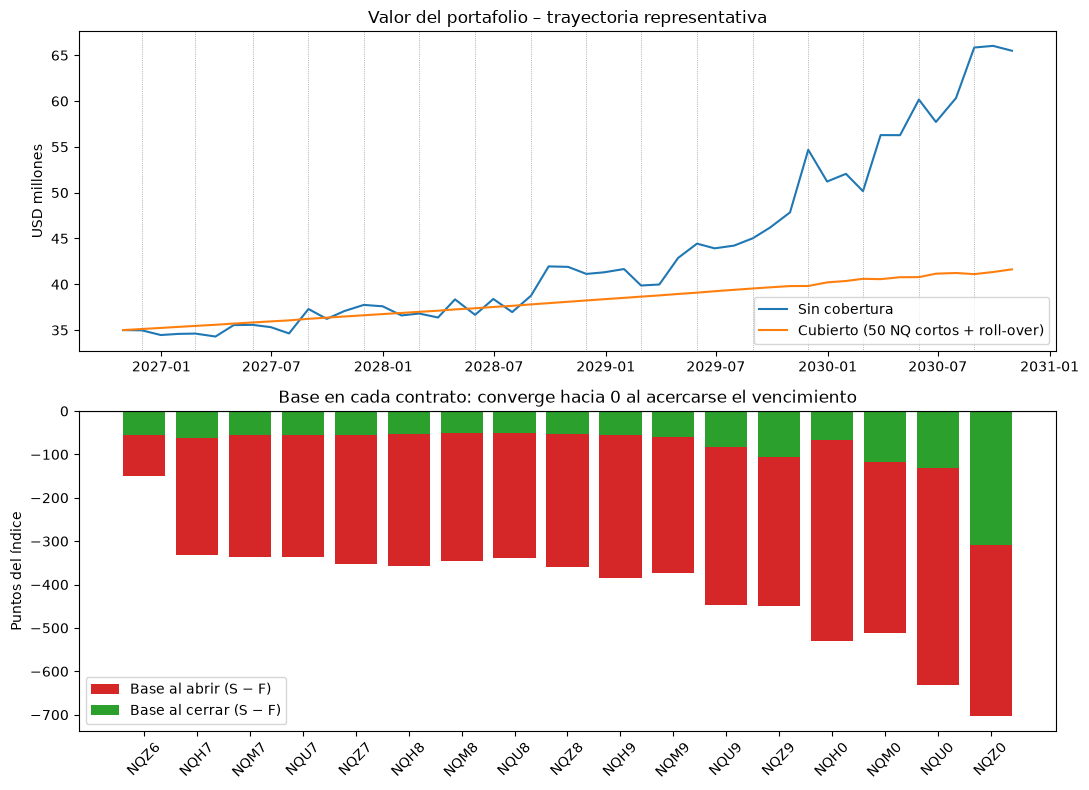

In [14]:
# 9.4 Gráfico: valor del portafolio sin cobertura vs. cubierto y base en cada roll
fig, ax = plt.subplots(2, 1, figsize=(11, 8))
ax[0].plot(evol.index, evol["V sin cobertura"] / 1e6, label="Sin cobertura")
ax[0].plot(evol.index, evol["V cubierto"] / 1e6, label="Cubierto (50 NQ cortos + roll-over)")
for f in pd.to_datetime(rolls["Cierre"].iloc[:-1]):
    ax[0].axvline(f, color="gray", lw=0.5, ls=":")                    # fechas de roll-over
ax[0].set_ylabel("USD millones"); ax[0].legend(); ax[0].set_title("Valor del portafolio – trayectoria representativa")
ax[1].bar(rolls.index, rolls["Base apertura"], color="tab:red", label="Base al abrir (S − F)")
ax[1].bar(rolls.index, rolls["Base cierre"], color="tab:green", label="Base al cerrar (S − F)")
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set_ylabel("Puntos del índice"); ax[1].legend(); ax[1].set_title("Base en cada contrato: converge hacia 0 al acercarse el vencimiento")
ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
fig.savefig(RAIZ / "outputs" / "figures" / "rollover_base.png", dpi=150)
plt.show()

**Interpretación:**

- **Lógica del roll-over:** Se negociaron 17 contratos (NQZ6 → NQZ0) en 16 renovaciones. Cada contrato se mantiene 3 meses, el primer contrato no dura los tres meses porque el NQZ6 vence el 18/12/2026 y el último solo serían 2 meses, hasta el fin del tiempo de la cobertura establecida en el laboratorio. 

La suma del P&G realizado de los 17 contratos (**−USD 23.85 M**) coincide exactamente con la suma de las liquidaciones mensuales del punto previo. El roll over solo cierra lo que ya se había liquidado mes a mes.

- **Análisis a fondo del reesultado:** 

    - El componente **spot** es de **−USD 29.36 M** y corresponde a la pérdida del corto porque el índice subió y la cobertura rechaza esa ganancia al alza.
    
    - El componente **base** es de **+USD 5.51 M** y es a favor del corto, como el futuro cotiza por encima del índice (contango), la base arranca negativa en cada contrato entre −330 y −700 puntos y por regla general estos se acercan a 0 a medida que se aproximan al vencimiento. 
    
    - Por regla general del ejercicio quien está en corto vende "caro" y recompra más cerca del spot. Esta ganancia aparece en cada roll over, por eso el spread promedio de renovación es de 355 puntos, es decir, USD 355 mil para 50 contratos.

- **Riesgo de base:** En la práctica la base cambia con la tasa de interés y con los dividendos esperados del índice ($c = r - q$), así que el roll yield no está garantizado: 
    
    - Si las tasas bajan, el contango se reduce y el corto gana menos en cada renovación. 
    - El futuro solo cubre la parte explicada por $\beta_p$ (R² = 0.56), así que el comportamiento propio de CSCO, ADI y PYPL queda sin cubrir.

- **Costos:** Son de USD 12,320 en los 4 años (1,700 lados × USD 7.247): comisión de IBKR, tasa de CME, tasa de la NFA y 1 tick de deslizamiento. El costo relevante de la cobertura no son las comisiones sino la **liquidez** para los **margin call**.


**Efecto sobre la rentabilidad**

| | Sin cobertura | Cubierto |
|---|---|---|
| Valor final | USD 65.49 M | USD 41.63 M |
| Rentabilidad anual | 16.96 % | **4.43 %** |
| Volatilidad anual | 14.99 % | **0.69 %** |
| Peor mes | −6.33 % | −0.30 % |

En nuestra posición de hedger, hacemos que el portafolio que veo a un producto muy similar de como lo es un bono, tesoro, porque se asemeja a la **tasa libre de riesgo**, la volatilidad cae sustancialmente alrededor de un 95% y la rentabilidad como se menciona queda como la tasa libre de riesgo ^TNX = 4.93. Queda un poco por debajo porque el futuro "paga" $c = r - q$ y no $r$ completo, además porque el 0.65% de la exposición quedó sin cubrir por el redondeo hacia abajo.

En específico en esta trayectoria que es alcista, la cobertura nos cuesta unos USD 23.9 M de ganancia, pero, con un escenario bajista el resultado puede cambiar notoriamente, lo evaluamos en los puntos posteriores. 



## Punto 10 – Valor esperado de la cobertura trimestral y tasa libre de riesgo (R12 – 7 %)

### 10.1 Tasa libre de riesgo

**Tasa aplicable:** ^TNX al **30/10/2026 = 4.929 %** anual (Yahoo Finance, `data/raw/tnx.csv`).

**Observación sobre el enunciado:** para aclarar en el laboratorio se describe la tasa ^TNX como el *"CBOE Interest Rate 1 to 3 Year Treasury Index"*, pero en realidad esta tasa representa a un periodo mucho más largo específicamente los 10 años. Sin embargo usamos ^TNX y no una tasa de corto plazo por estas razones:

1. El horizonte de inversión es de **4 años**.
2. Es el bono del Tesoro más líquido y la referencia más usada como tasa libre de riesgo en valoración.

**Conversión a tasa mensual y trimestral:** Se usa la **tasa efectiva** (capitalización compuesta), porque los valores del portafolio se acumulan mes a mes y la tasa compuesta es coherente con ese crecimiento:

$$r_{f,m} = (1 + r_f)^{1/12} - 1 \qquad r_{f,q} = (1 + r_f)^{1/4} - 1$$

Su alternativa sería la **tasa nominal** ($r_f/12$, $r_f/4$) que supone interés simple. El problema es que al capitalizarla mensualmente se llega a una tasa anual mayor que la del ^TNX, así que sobrestimaría el rendimiento libre de riesgo.

### 10.2 Valor esperado de la posición cubierta

El **valor esperado** se obtiene promediando las **10,000 trayectorias simuladas**. Para cada trayectoria se repite exactamente el paso a paso de los rubros 8 y 9: 

 - Los mismos 50 contratos posición corta.
 - El mismo calendario de roll-over.
 - Los precios al tick. 
 - El CAPM para el portafolio y los costos.
 - Cálculo al cierre de cada trimestre:

° $E[V_{sin}]$ y $E[V_{cub}]$: el valor esperado del portafolio sin cobertura y cubierto.

° Su desviación estándar y su **percentil 5**, es decir, el valor que solo se supera hacia abajo en el 5% de los escenarios.

° El **valor teórico libre de riesgo**: $V_0 (1 + r_{f,q})^q$. Si la cobertura elimina el riesgo sistemático, el portafolio cubierto debería crecer cerca de esta tasa.

In [15]:
# 10.1 Tasa libre de riesgo: conversión efectiva vs. nominal
rf_q = (1 + rf) ** (1 / 4) - 1                      # tasa efectiva trimestral (rf y rf_m vienen del Punto 9)
tasas = pd.DataFrame({
    "Efectiva (compuesta)": [rf_m, rf_q, (1 + rf_m) ** 12 - 1],
    "Nominal (simple)":     [rf / 12, rf / 4, (1 + rf / 12) ** 12 - 1],
}, index=["Mensual", "Trimestral", "Anual equivalente al capitalizar"])
print(f"^TNX al 30/10/2026 = {rf * 100:.3f} → r_f = {rf:.5f}")
tasas.style.format("{:.4%}")

^TNX al 30/10/2026 = 4.929 → r_f = 0.04929


,Efectiva (compuesta),Nominal (simple)
Mensual,0.4018%,0.4107%
Trimestral,1.2101%,1.2322%
Anual equivalente al capitalizar,4.9290%,5.0419%


In [16]:
# 10.2 Las 10,000 trayectorias: futuros, portafolio sin cobertura y cubierto, y cuenta de margen
S_arr = S_sim.values                                    # (49 fechas × 10,000 trayectorias)
pg_fut = np.zeros((n_mes, n_sim))                       # P&G mensual del corto en cada trayectoria
for t in range(1, n_mes + 1):
    cod, v = contrato_del_mes(fechas[t])                # mismo calendario de contratos del Punto 8
    F_ini = precio_futuro(S_arr[t - 1], fechas[t - 1], v)
    F_fin = precio_futuro(S_arr[t],     fechas[t],     v)
    pg_fut[t - 1] = -(F_fin - F_ini) / NQ["tick"] * NQ["valor_tick"] * N   # ticks × valor del tick × N (corto)

r_m_sim = S_arr[1:] / S_arr[:-1] - 1                    # rendimiento mensual del índice en cada trayectoria
r_p_sim = rf_m + beta_p * (r_m_sim - rf_m)              # CAPM (como en el Punto 9 y en el Excel)
V_sin_sim = Vp * np.vstack([np.ones(n_sim), np.cumprod(1 + r_p_sim, axis=0)])
V_cub_sim = V_sin_sim + np.vstack([np.zeros(n_sim), np.cumsum(pg_fut, axis=0)]) \
            - np.cumsum(costos_mes)[:, None]            # cubierto = acciones + futuros − costos

# Cuenta de margen en cada trayectoria (misma regla del Punto 8)
saldo = np.full(n_sim, VGI0); mc_ant = np.zeros(n_sim)
n_calls = np.zeros(n_sim); repuesto = np.zeros(n_sim)
for t in range(n_mes):
    saldo = saldo + mc_ant + pg_fut[t]
    mc_ant = np.where(saldo < VGM, VGI0 - saldo, 0.0)
    n_calls += mc_ant > 0; repuesto += mc_ant

# Control: la trayectoria elegida en el Punto 8 debe dar el mismo resultado
print(f"Control trayectoria #{k_med}: V cubierto final = {V_cub_sim[-1, k_med]:,.0f} vs. Punto 9 = {V_cub[-1]:,.0f}")

Control trayectoria #849: V cubierto final = 41,629,336 vs. Punto 9 = 41,629,336


In [17]:
# 10.3 Valor esperado trimestral: sin cobertura vs. cubierto vs. libre de riesgo
idx_q = np.arange(0, n_mes + 1, 3)                      # meses 0, 3, 6, …, 48 (cierre de cada trimestre)
q = np.arange(len(idx_q))                               # trimestre 0..16
ve = pd.DataFrame({
    "Fecha": fechas[idx_q].date,
    "E[V] sin cobertura": V_sin_sim[idx_q].mean(axis=1),
    "E[V] cubierto": V_cub_sim[idx_q].mean(axis=1),
    "V libre de riesgo": Vp * (1 + rf_q) ** q,
    "σ sin cobertura": V_sin_sim[idx_q].std(axis=1),
    "σ cubierto": V_cub_sim[idx_q].std(axis=1),
    "P5 sin cobertura": np.percentile(V_sin_sim[idx_q], 5, axis=1),
    "P5 cubierto": np.percentile(V_cub_sim[idx_q], 5, axis=1),
}, index=[f"T{k}" for k in q])
# Valor esperado del resultado de la cobertura (futuros − costos) en cada trimestre
ve["E[cobertura] trimestre"] = (ve["E[V] cubierto"] - ve["E[V] sin cobertura"]).diff()
ve.to_csv(PROC / "valor_esperado_trimestral.csv")
ve.style.format({c: "{:,.0f}" for c in ve.columns if c != "Fecha"}, na_rep="—")

,Fecha,E[V] sin cobertura,E[V] cubierto,V libre de riesgo,σ sin cobertura,σ cubierto,P5 sin cobertura,P5 cubierto,E[cobertura] trimestre
T0,2026-10-30,"35,000,000","34,999,638","35,000,000",0,0,"35,000,000","34,999,638",—
T1,2027-01-29,"36,481,213","35,364,231","35,423,537","2,883,157","35,008","31,935,287","35,302,389","-1,116,620"
T2,2027-04-30,"38,099,517","35,737,364","35,852,200","4,239,667","72,730","31,525,559","35,603,584","-1,245,171"
T3,2027-07-30,"39,708,113","36,118,450","36,286,050","5,410,141","118,282","31,498,390","35,901,846","-1,227,509"
T4,2027-10-29,"41,418,633","36,508,259","36,725,150","6,495,715","174,448","31,763,987","36,198,137","-1,320,712"
T5,2028-01-31,"43,214,903","36,917,814","37,169,564","7,534,412","227,570","32,026,196","36,500,630","-1,386,715"
T6,2028-04-28,"45,134,246","37,306,999","37,619,355","8,685,613","301,665","32,421,729","36,771,200","-1,530,157"
T7,2028-07-31,"47,091,810","37,728,930","38,074,589","9,843,300","386,780","32,679,729","37,051,678","-1,535,633"
T8,2028-10-31,"49,097,394","38,156,789","38,535,333","10,901,029","465,538","33,258,845","37,351,887","-1,577,726"
T9,2029-01-31,"51,199,153","38,588,528","39,001,651","12,095,001","566,092","33,821,581","37,597,101","-1,670,019"


In [18]:
# 10.4 Resumen a 4 años y riesgo de liquidez de la cobertura
def resumen(V):
    R = V[-1] / Vp - 1                                   # rentabilidad total de cada trayectoria
    return {"E[valor final] (USD)": V[-1].mean(), "E[rentabilidad anual]": (V[-1].mean() / Vp) ** (1/4) - 1,
            "σ del valor final (USD)": V[-1].std(), "Percentil 5 del valor final (USD)": np.percentile(V[-1], 5),
            "Percentil 95 del valor final (USD)": np.percentile(V[-1], 95),
            "Prob. de terminar por debajo de 35 M": (V[-1] < Vp).mean(),
            "Prob. de no superar la tasa libre de riesgo": (R < (1 + rf) ** 4 - 1).mean()}

res10 = pd.DataFrame({"Sin cobertura": resumen(V_sin_sim), "Cubierto": resumen(V_cub_sim)})
res10.loc["E[valor final] (USD)", "Libre de riesgo"] = Vp * (1 + rf) ** 4
res10.to_csv(PROC / "resumen_valor_esperado.csv")
display(res10.style.format(lambda x: "—" if pd.isna(x) else (f"{x:,.0f}" if abs(x) > 10 else f"{x:.2%}")))

liq = pd.Series({"Llamados al margen esperados (de 48 meses)": n_calls.mean(),
                 "Prob. de al menos un llamado": (n_calls > 0).mean(),
                 "Reposición total esperada (USD)": repuesto.mean(),
                 "Reposición total – percentil 95 (USD)": np.percentile(repuesto, 95)})
liq.to_frame("Cuenta de margen – 10,000 trayectorias").style.format("{:,.2f}")

,Sin cobertura,Cubierto,Libre de riesgo
E[valor final] (USD),"68,912,453","41,742,614","42,427,767"
E[rentabilidad anual],18.46%,4.50%,—
σ del valor final (USD),"21,952,869","1,812,271",—
Percentil 5 del valor final (USD),"39,527,394","38,889,718",—
Percentil 95 del valor final (USD),"110,251,455","43,579,875",—
Prob. de terminar por debajo de 35 M,2.19%,1.16%,—
Prob. de no superar la tasa libre de riesgo,7.81%,66.61%,—


,"Cuenta de margen – 10,000 trayectorias"
Llamados al margen esperados (de 48 meses),13.82
Prob. de al menos un llamado,0.99
Reposición total esperada (USD),"32,025,245.48"
Reposición total – percentil 95 (USD),"75,635,225.00"


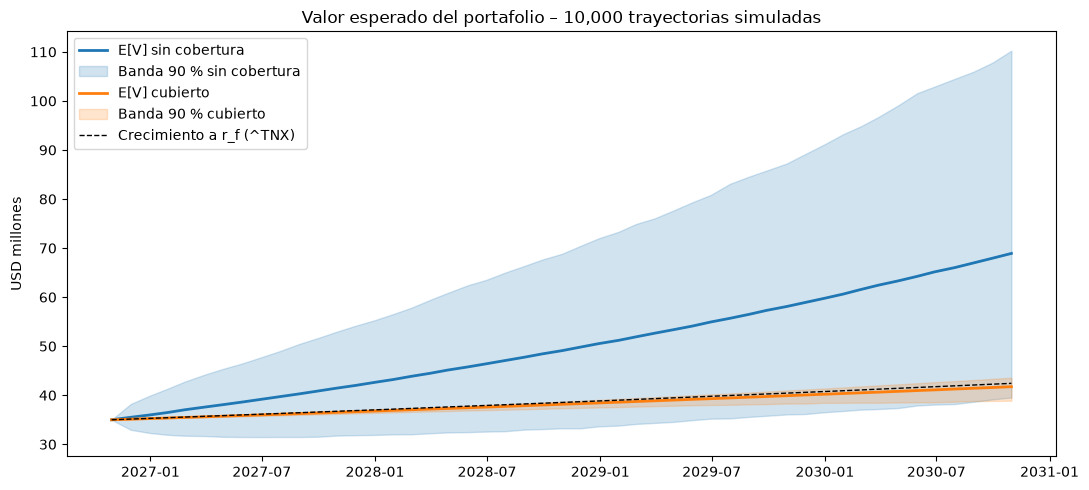

In [19]:
# 10.5 Gráfico: valor esperado y banda del 90 % (P5–P95)
fig, ax = plt.subplots(figsize=(11, 5))
for V, nombre, color in [(V_sin_sim, "Sin cobertura", "tab:blue"), (V_cub_sim, "Cubierto", "tab:orange")]:
    ax.plot(fechas, V.mean(axis=1) / 1e6, color=color, lw=2, label=f"E[V] {nombre.lower()}")
    ax.fill_between(fechas, np.percentile(V, 5, axis=1) / 1e6, np.percentile(V, 95, axis=1) / 1e6,
                    color=color, alpha=0.2, label=f"Banda 90 % {nombre.lower()}")
ax.plot(fechas[idx_q], ve["V libre de riesgo"] / 1e6, "k--", lw=1, label="Crecimiento a r_f (^TNX)")
ax.set_ylabel("USD millones"); ax.legend(loc="upper left")
ax.set_title("Valor esperado del portafolio – 10,000 trayectorias simuladas")
plt.tight_layout()
fig.savefig(RAIZ / "outputs" / "figures" / "valor_esperado_trimestral.png", dpi=150)
plt.show()

**Interpretación:**

- **Tasa libre de riesgo:** La tasa trimestral efectiva es del 1.2101% y la mensual del 0.4018%. Si se usaran las nominales (1.2322% y 0.4107%) y se capitalizaran la tasa anual sería del 5.04% en lugar del 4.929% que es la observada, así que el rendimiento libre de riesgo quedaría sobrestimado, por esta razon usamos las tasas efectivas.

- **Valor esperado de la posición cubierta:** 
    
    - A 4 años, $E[V_{cub}]$ = **USD 41.74 M** (4.50 % anual), está muy cerca de la tasa libre de riesgo, USD 42.43 M (4.929 % anual). 
    - Este resultado es el que predice la teoría, ya que, al neutralizar el riesgo sistemático, el portafolio cubierto se comporta casi como un activo libre de riesgo. 

**Sin cobertura vs. cubierto.**

| | Sin cobertura | Cubierto |
|---|---|---|
| E[valor final] | USD 68.91 M (18.46 % anual) | USD 41.74 M (4.50 % anual) |
| σ del valor final | USD 21.95 M | **USD 1.81 M** (−92 %) |
| Rango percentiles P5–P95 | 39.53 M – 110.25 M | 38.89 M – 43.58 M |
| Prob. de terminar por debajo de USD 35 M | 2.19 % | 1.16 % |

- **La cobertura reduce tanto el riesgo como la rentabilidad:** 
    
    - El riesgo cae drásticamente, por lo que la dispersión del valor final se reduce en un 92% y rango entre los percentiles casos P5-P90 pasa de USD 71 M de ancho a menos de USD 5 M. 
    
    - Pero la rentabilidad esperada también cae, de 18.46 % a 4.50 % anual. Como inversionistas entregamos la prima de riesgo de mercado a cambio de un perfil muy conservador. En cada trimestre el resultado esperado de la cobertura es negativo, entre −USD 1.1 M y −USD 2.4 M (columna *E[cobertura] trimestre*), porque el tendencia o drift histórico del índice es positivo.


- **Costo de liquidez esperado:** En las 10,000 trayectorias se esperan **13.8 llamados al margen** en 48 meses. El 99% de los escenarios tiene al menos un **margin call** y la reposición total esperada es de **USD 32.0 M**. Aunque estos depósitos lo conpensamos con la valorización de las nuestras acciones adquiridas en el portafolio, como entidad debemos de tener **caja suficiente**, porque una cosa es que las acciones se valorizan en el tiempo y no se haga efectivo sus rendimiento y la caja es porque el margen se repone en efectivo.

## Punto 11 – Rendimiento y valor esperado mensual: tres enfoques y dividendos (R13 – 6 %)

En este punto vemos, mes a mes durante los 48 meses, cuánto esperamos ganar y cuánto valdría la cartera desde tres miradas distintas:

| Enfoque | ¿Qué responde? | Cómo lo calculamos |
|---|---|---|
| **(a) Sin cobertura** | ¿Cuánto rinde la cartera si no nos cubrimos? | Promedio de las 10,000 simulaciones (Punto 10) + dividendos |
| **(b) Cubierto con futuros** | ¿Cuánto rinde si mantenemos los 50 contratos cortos? | Acciones + futuros − costos, promediado en las 10,000 simulaciones + dividendos |
| **(c) Ajustado por VaR** | ¿Cuánto valdría la cartera si nos toca un mes malo? | Valor esperado del mes anterior × (1 − VaR del Punto 4) |

**Sobre el enfoque (c):** usamos los VaR mensuales que ya calculamos en el Punto 4: sin cobertura, 8.23 % al 95 % y 11.91 % al 99 %; cubierto, 5.11 % y 7.66 %. La ventaja de este enfoque es que tiene en cuenta el **riesgo propio** de CSCO, ADI y PYPL (el 44 % que no depende del mercado). La simulación de los Puntos 8 a 10 no lo incluye, porque supone que nuestro portafolio se mueve exactamente β veces el índice. Por eso este enfoque nos muestra de forma más realista el riesgo que nos **queda** después de cubrirnos.

**Dividendos:** las tres empresas pagan dividendos (Punto 0). Para cada una sumamos lo que pagó en los últimos 12 meses (31/10/2025 a 30/10/2026) y lo dividimos entre su precio al 30/10/2026. El del portafolio es el promedio ponderado con nuestros pesos (40 % CSCO, 45 % ADI y 15 % PYPL). Como el dato es anual, lo pasamos a mensual con la tasa efectiva: $q_m = (1+q)^{1/12} - 1$.

**Cómo evitamos contar los dividendos dos veces?** El índice que simulamos (^NDX) solo refleja la variación del **precio** de las acciones, no los dividendos (Punto 0). Entonces sumamos los dividendos aparte, como un ingreso adicional de cada mes:

$$r^{total}_{t} = r^{precio}_{t} + q_m \qquad D_t = E[V_{t-1}] \cdot q_m$$

**Un punto importante:** cubrirnos con futuros **no nos quita los dividendos**. Seguimos siendo dueños de las acciones, así que los seguimos recibiendo.

In [20]:
# 11.1 Dividend yield de cada acción y del portafolio (últimos 12 meses al 30/10/2026)
div   = pd.read_csv(RAIZ / "data" / "raw" / "dividendos.csv", index_col=0, parse_dates=True)
acc   = ["CSCO", "ADI", "PYPL"]
pesos = pd.read_csv(PROC / "portafolios_markowitz.csv", index_col=0)["Máx. Sharpe"]
w     = pd.Series({a: pesos[f"Peso {a}"] for a in acc})            # 40 % | 45 % | 15 %

div_12m = div.loc["2025-10-31":"2026-10-30", acc].sum()             # dividendos pagados en los últimos 12 meses (USD por acción)
precio  = close.loc["2026-10-30", acc]                              # precio al 30/10/2026
q_acc   = div_12m / precio                                          # dividend yield anual de cada acción
q_p     = (w * q_acc).sum()                                         # dividend yield del portafolio (ponderado)
q_m     = (1 + q_p) ** (1 / 12) - 1                                 # tasa efectiva mensual

tabla_div = pd.DataFrame({"Peso": w, "Dividendos 12 m (USD/acción)": div_12m, "Precio 30/10/2026": precio,
                          "Dividend yield anual": q_acc, "Aporte al portafolio": w * q_acc})
print(f"Dividend yield del portafolio: q = {q_p:.4%} anual → q_m = {q_m:.4%} mensual "
      f"(≈ USD {Vp * q_m:,.0f} el primer mes)")
tabla_div.style.format({"Peso": "{:.0%}", "Dividendos 12 m (USD/acción)": "{:.2f}", "Precio 30/10/2026": "{:,.2f}",
                        "Dividend yield anual": "{:.2%}", "Aporte al portafolio": "{:.2%}"})

Dividend yield del portafolio: q = 1.2493% anual → q_m = 0.1035% mensual (≈ USD 36,232 el primer mes)


,Peso,Dividendos 12 m (USD/acción),Precio 30/10/2026,Dividend yield anual,Aporte al portafolio
CSCO,40%,1.67,104.51,1.60%,0.64%
ADI,45%,4.29,417.11,1.03%,0.46%
PYPL,15%,0.56,57.01,0.98%,0.15%


In [21]:
# 11.2 Rendimiento y valor esperado mensual bajo los tres enfoques
var_tab = pd.read_csv(PROC / "var_cubierto_vs_sin.csv", index_col=0)      # VaR mensual del Punto 4
var95_sin, var99_sin = var_tab.loc["VaR 95%", "Sin cobertura (%)"], var_tab.loc["VaR 99%", "Sin cobertura (%)"]
var95_cub, var99_cub = var_tab.loc["VaR 95%", "Cubierto (%)"],      var_tab.loc["VaR 99%", "Cubierto (%)"]

EV_sin = V_sin_sim.mean(axis=1)                                     # E[V_t] sin cobertura (precio), meses 0..48
EV_cub = V_cub_sim.mean(axis=1)                                     # E[V_t] cubierto (precio)
r_sin  = EV_sin[1:] / EV_sin[:-1] - 1                               # rendimiento esperado mensual por precio
r_cub  = EV_cub[1:] / EV_cub[:-1] - 1
D_sin  = EV_sin[:-1] * q_m                                          # dividendos esperados del mes (USD)
D_cub  = EV_cub[:-1] * q_m

enf = pd.DataFrame({
    "Trimestre": [f"T{(t - 1) // 3 + 1}" for t in range(1, n_mes + 1)],
    # (a) sin cobertura
    "(a) r precio": r_sin, "(a) r total": r_sin + q_m,
    "(a) E[V]": EV_sin[1:], "(a) E[V] + div. acum.": EV_sin[1:] + np.cumsum(D_sin),
    # (b) cubierto
    "(b) r precio": r_cub, "(b) r total": r_cub + q_m,
    "(b) E[V]": EV_cub[1:], "(b) E[V] + div. acum.": EV_cub[1:] + np.cumsum(D_cub),
    # (c) ajustado por VaR: valor si en el mes ocurre la pérdida del VaR (sobre el valor esperado del mes anterior)
    "(c) V VaR95 sin": EV_sin[:-1] * (1 - var95_sin), "(c) V VaR99 sin": EV_sin[:-1] * (1 - var99_sin),
    "(c) V VaR95 cub": EV_cub[:-1] * (1 - var95_cub), "(c) V VaR99 cub": EV_cub[:-1] * (1 - var99_cub),
}, index=pd.Index(range(1, n_mes + 1), name="Mes"))
enf.insert(0, "Fecha", fechas[1:].date)
enf.to_csv(PROC / "tres_enfoques_mensual.csv")

pct = [c for c in enf.columns if " r " in f" {c} "]
enf.style.format({c: "{:+.3%}" for c in pct} | {c: "{:,.0f}" for c in enf.columns if c not in pct + ["Fecha", "Trimestre"]})

,Fecha,Trimestre,(a) r precio,(a) r total,(a) E[V],(a) E[V] + div. acum.,(b) r precio,(b) r total,(b) E[V],(b) E[V] + div. acum.,(c) V VaR95 sin,(c) V VaR99 sin,(c) V VaR95 cub,(c) V VaR99 cub
Mes,,,,,,,,,,,,,,
1,2026-11-30,T1,+1.442%,+1.545%,"35,504,576","35,540,809",+0.353%,+0.457%,"35,123,287","35,159,519","32,121,021","30,829,899","33,210,189","32,318,868"
2,2026-12-31,T1,+1.359%,+1.462%,"35,987,058","36,060,045",+0.349%,+0.452%,"35,245,735","35,318,326","32,584,093","31,274,357","33,327,517","32,433,047"
3,2027-01-29,T1,+1.373%,+1.477%,"36,481,213","36,591,454",+0.336%,+0.440%,"35,364,231","35,473,309","33,026,888","31,699,354","33,443,704","32,546,116"
4,2027-02-26,T2,+1.540%,+1.644%,"37,043,026","37,191,032",+0.330%,+0.434%,"35,481,015","35,626,702","33,480,395","32,134,632","33,556,142","32,655,536"
5,2027-03-31,T2,+1.504%,+1.607%,"37,599,974","37,786,328",+0.371%,+0.475%,"35,612,646","35,795,064","33,995,995","32,629,507","33,666,955","32,763,374"
6,2027-04-30,T2,+1.329%,+1.432%,"38,099,517","38,324,794",+0.350%,+0.454%,"35,737,364","35,956,648","34,507,131","33,120,098","33,791,856","32,884,924"
7,2027-05-31,T3,+1.389%,+1.492%,"38,628,561","38,893,279",+0.362%,+0.466%,"35,866,737","36,123,016","34,965,583","33,560,122","33,910,197","33,000,089"
8,2027-06-30,T3,+1.404%,+1.508%,"39,170,913","39,475,619",+0.348%,+0.452%,"35,991,707","36,285,116","35,451,110","34,026,133","34,032,956","33,119,552"
9,2027-07-30,T3,+1.371%,+1.475%,"39,708,113","40,053,369",+0.352%,+0.456%,"36,118,450","36,449,118","35,948,849","34,503,865","34,151,536","33,234,951"


In [22]:
# 11.3 Resumen: rendimiento mensual promedio y valor esperado a 4 años
def anual(r_m): return (1 + r_m) ** 12 - 1
res11 = pd.DataFrame({
    "Rend. mensual promedio (precio)": [enf["(a) r precio"].mean(), enf["(b) r precio"].mean(), -var95_sin, -var95_cub],
    "Rend. mensual promedio (total, con dividendos)": [enf["(a) r total"].mean(), enf["(b) r total"].mean(), np.nan, np.nan],
    "Rend. anual equivalente (total)": [anual(enf["(a) r total"].mean()), anual(enf["(b) r total"].mean()), np.nan, np.nan],
    "Valor esperado a 4 años sin dividendos (USD)": [EV_sin[-1], EV_cub[-1], np.nan, np.nan],
    "Dividendos acumulados (USD)": [D_sin.sum(), D_cub.sum(), np.nan, np.nan],
    "Valor esperado a 4 años con dividendos (USD)": [EV_sin[-1] + D_sin.sum(), EV_cub[-1] + D_cub.sum(), np.nan, np.nan],
    "Pérdida del mes en escenario VaR 95 % (USD, 1.er mes)": [np.nan, np.nan, Vp * var95_sin, Vp * var95_cub],
    "Pérdida del mes en escenario VaR 99 % (USD, 1.er mes)": [np.nan, np.nan, Vp * var99_sin, Vp * var99_cub],
}, index=["(a) Sin cobertura", "(b) Cubierto con futuros", "(c) VaR – sin cobertura", "(c) VaR – cubierto"]).T
res11.to_csv(PROC / "resumen_tres_enfoques.csv")
res11.style.format(lambda x: "—" if pd.isna(x) else (f"{x:,.0f}" if abs(x) > 10 else f"{x:+.3%}"))

,(a) Sin cobertura,(b) Cubierto con futuros,(c) VaR – sin cobertura,(c) VaR – cubierto
Rend. mensual promedio (precio),+1.421%,+0.368%,-8.226%,-5.113%
"Rend. mensual promedio (total, con dividendos)",+1.525%,+0.471%,—,—
Rend. anual equivalente (total),+19.915%,+5.804%,—,—
Valor esperado a 4 años sin dividendos (USD),"68,912,453","41,742,614",—,—
Dividendos acumulados (USD),"2,468,632","1,895,851",—,—
Valor esperado a 4 años con dividendos (USD),"71,381,085","43,638,466",—,—
"Pérdida del mes en escenario VaR 95 % (USD, 1.er mes)",—,—,"2,878,979","1,789,467"
"Pérdida del mes en escenario VaR 99 % (USD, 1.er mes)",—,—,"4,170,101","2,680,797"


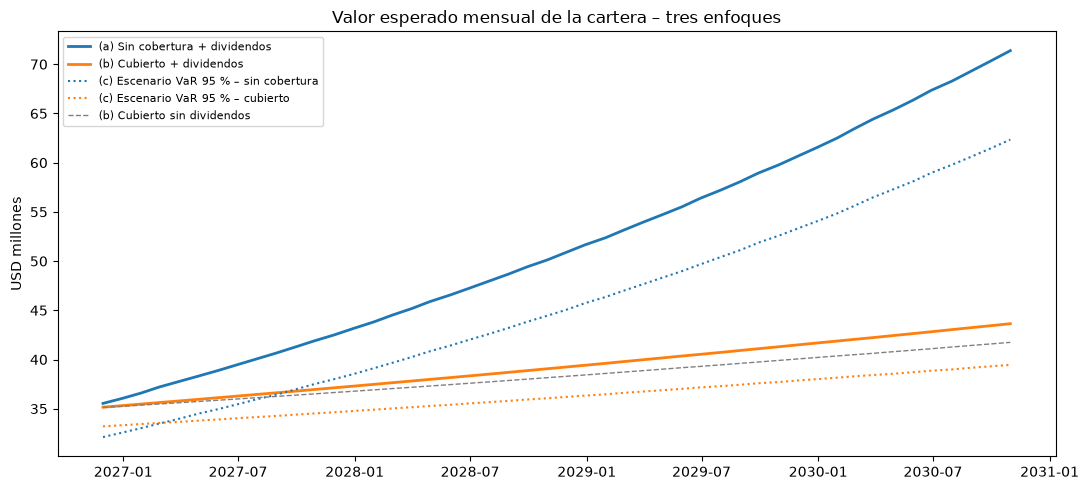

In [23]:
# 11.4 Gráfico: valor esperado mensual bajo los tres enfoques
fig, ax = plt.subplots(figsize=(11, 5))
x = pd.to_datetime(enf["Fecha"])
ax.plot(x, enf["(a) E[V] + div. acum."] / 1e6, color="tab:blue", lw=2, label="(a) Sin cobertura + dividendos")
ax.plot(x, enf["(b) E[V] + div. acum."] / 1e6, color="tab:orange", lw=2, label="(b) Cubierto + dividendos")
ax.plot(x, enf["(c) V VaR95 sin"] / 1e6, color="tab:blue", ls=":", label="(c) Escenario VaR 95 % – sin cobertura")
ax.plot(x, enf["(c) V VaR95 cub"] / 1e6, color="tab:orange", ls=":", label="(c) Escenario VaR 95 % – cubierto")
ax.plot(x, enf["(b) E[V]"] / 1e6, color="gray", lw=1, ls="--", label="(b) Cubierto sin dividendos")
ax.set_ylabel("USD millones"); ax.legend(fontsize=8, loc="upper left")
ax.set_title("Valor esperado mensual de la cartera – tres enfoques")
plt.tight_layout()
fig.savefig(RAIZ / "outputs" / "figures" / "tres_enfoques_mensual.png", dpi=150)
plt.show()

**Interpretación:**

- **Dividendos:** las tres acciones pagan dividendo: CSCO 1.60 %, ADI 1.03 % y PYPL 0.98 % al año. Para nuestro portafolio esto da un **1.25 % anual** (0.1035 % mensual), unos USD 36 mil el primer mes.
    - En los 4 años recibimos cerca de **USD 2.47 M** sin cobertura y **USD 1.90 M** con cobertura.
    - Con cobertura recibimos menos solo porque la cartera vale menos en promedio, no porque los perdamos. Los dividendos no dependen del índice, así que el corto no los toca.

- **(a) Sin cobertura:** esperamos ganar 1.42 % al mes por precio y 1.52 % contando dividendos (≈ 19.9 % al año). A 4 años la cartera valdría USD 68.91 M, o **USD 71.38 M con dividendos**.
    - Es el enfoque que más rinde, pero también el más incierto: el valor final puede variar en ± USD 21.95 M (Punto 10).

- **(b) Cubierto:** esperamos ganar 0.37 % al mes por precio y 0.47 % con dividendos (≈ **5.80 % al año**). A 4 años la cartera valdría USD 41.74 M, o **USD 43.64 M con dividendos**.
    - Gracias a los dividendos, la cartera cubierta **rinde más que la tasa libre de riesgo** (4.93 %). Con la cobertura renunciamos a la ganancia del mercado, pero seguimos cobrando los dividendos de nuestras acciones.

- **(c) Ajustado por VaR:** si el primer mes nos toca el escenario malo del VaR 95 % (uno de cada 20 meses), sin cobertura perderíamos USD 2.88 M y cubiertos USD 1.79 M. Al 99 % las pérdidas serían de USD 4.17 M y USD 2.68 M.
    - Aquí la cobertura reduce la pérdida **solo un 38 %**, mientras que en la simulación del Punto 10 el riesgo bajaba un 92 %.
    - La diferencia es el riesgo propio de cada empresa: si a PYPL le va mal por un tema suyo, el futuro sobre el índice no nos protege. Por eso, para saber cuánto colchón necesitamos ante un mes malo, este es el enfoque más realista.

- **En resumen:** sin cobertura ganamos más pero con mucha incertidumbre; cubiertos ganamos cerca de la tasa libre de riesgo más los dividendos; y aun cubiertos podemos perder ≈ USD 1.8 M en un mes malo por el comportamiento propio de nuestras acciones.

## Punto 12 – Sensibilidad a la beta: β = 0.6 y β = 1.5 (R14 – 6 %)

El enunciado nos pide suponer que nuestro portafolio tuviera una beta de 0.6 o de 1.5 en lugar de la nuestra (0.8206). Para cada caso repetimos los cálculos con la misma fórmula del Punto 6, el mismo contrato (NQZ6, $F_0$ = 28,534), los mismos márgenes y las mismas 10,000 simulaciones:

$$N^* = \frac{\beta \cdot V_p}{F_0 \cdot Q_F} \qquad \text{Exposición al mercado} = \beta \cdot V_p \qquad \Delta V \approx \beta \cdot \Delta\text{índice} \cdot V_p$$

**Qué nos dice la beta?** Qué tanto se mueve nuestro portafolio cuando se mueve el índice:
- Con β = 1.5, si el Nasdaq-100 cae 10 %, nuestro portafolio cae cerca de 15 %.
- Con β = 0.6, solo cae cerca de 6 %.

El futuro se mueve igual que el índice (β = 1). Por eso, si nuestro portafolio se mueve 1.5 veces más que el índice, necesitamos más contratos para compensarlo: **a mayor beta, más contratos**. Mantenemos el mismo criterio del Punto 6 de redondear hacia abajo.

In [24]:
# 12.1 Número de contratos, exposición y sensibilidad para cada beta
casos = {"β = 0.6": 0.6, f"β = {beta_p} (base)": beta_p, "β = 1.5": 1.5}
filas = []
for nombre, b in casos.items():
    n_opt = b * Vp / expo_contrato                          # N* = β·Vp / (F0·Q_F)
    n_ent = int(np.floor(n_opt))                            # redondeo hacia abajo (criterio del Punto 6)
    caida = -0.10                                           # escenario: el índice cae 10 %
    dV    = b * caida * Vp                                  # cambio del portafolio ≈ β·Δíndice·Vp
    F1    = np.round(F0 * (1 + caida) / NQ["tick"]) * NQ["tick"]
    pg    = -(F1 - F0) / NQ["tick"] * NQ["valor_tick"] * n_ent   # P&G del corto con ticks
    filas.append({"Caso": nombre, "β": b, "N*": n_opt, "N (contratos)": n_ent,
                  "Exposición sistemática (USD)": b * Vp, "Exposición cubierta (USD)": n_ent * expo_contrato,
                  "Razón de cobertura": n_ent / n_opt,
                  "VGI0 total (USD)": n_ent * VGI0_c, "VGM total (USD)": n_ent * VGM_c,
                  "Valor tick posición (USD)": n_ent * NQ["valor_tick"],
                  "Δ portafolio si índice −10 % (USD)": dV, "P&G corto si índice −10 % (USD)": pg,
                  "Neto cubierto (USD)": dV + pg})
sens = pd.DataFrame(filas).set_index("Caso").T
sens.to_csv(PROC / "sensibilidad_beta.csv")
sens.style.format(lambda x: f"{x:,.4f}" if abs(x) < 10 else f"{x:,.0f}")

Caso,β = 0.6,β = 0.8206 (base),β = 1.5
β,0.6000,0.8206,1.5000
N*,37,50,92
N (contratos),36,50,91
Exposición sistemática (USD),"21,000,000","28,721,000","52,500,000"
Exposición cubierta (USD),"20,544,480","28,534,000","51,931,880"
Razón de cobertura,0.9783,0.9935,0.9892
VGI0 total (USD),"1,560,517","2,167,385","3,944,641"
VGM total (USD),"1,418,652","1,970,350","3,586,037"
Valor tick posición (USD),180,250,455
Δ portafolio si índice −10 % (USD),"-2,100,000","-2,872,100","-5,250,000"


In [25]:
# 12.2 Efecto sobre la cobertura con las 10,000 trayectorias: valor final, riesgo y llamados al margen
def evaluar(b, n_ent):
    r_p_b = rf_m + b * (r_m_sim - rf_m)                                      # CAPM con la beta hipotética
    V_s   = Vp * np.cumprod(1 + r_p_b, axis=0)[-1]                           # valor final sin cobertura
    pg_b  = pg_fut * (n_ent / N)                                             # P&G del corto escalado a n_ent contratos
    cost  = costos_mes.sum() * n_ent / N
    V_c   = V_s + pg_b.sum(axis=0) - cost                                    # valor final cubierto
    VGI0_b, VGM_b = n_ent * VGI0_c, n_ent * VGM_c                            # márgenes escalados
    sal = np.full(n_sim, VGI0_b); mc = np.zeros(n_sim); nc = np.zeros(n_sim); rep = np.zeros(n_sim)
    for t in range(n_mes):
        sal = sal + mc + pg_b[t]
        mc = np.where(sal < VGM_b, VGI0_b - sal, 0.0); nc += mc > 0; rep += mc
    return {"E[V final] sin cobertura": V_s.mean(), "σ sin cobertura": V_s.std(),
            "E[V final] cubierto": V_c.mean(), "σ cubierto": V_c.std(),
            "Reducción de σ": 1 - V_c.std() / V_s.std(),
            "E[rent. anual] sin cobertura": (V_s.mean() / Vp) ** 0.25 - 1,
            "E[rent. anual] cubierto": (V_c.mean() / Vp) ** 0.25 - 1,
            "Llamados al margen esperados": nc.mean(), "Reposición esperada (USD)": rep.mean()}

sens_mc = pd.DataFrame({c: evaluar(sens.loc["β", c], int(sens.loc["N (contratos)", c])) for c in sens.columns})
sens_mc.to_csv(PROC / "sensibilidad_beta_montecarlo.csv")
sens_mc.style.format(lambda x: f"{x:,.0f}" if abs(x) > 100 else f"{x:.2%}" if abs(x) < 1 else f"{x:,.2f}")

,β = 0.6,β = 0.8206 (base),β = 1.5
E[V final] sin cobertura,"60,525,060","68,912,453","102,496,018"
σ sin cobertura,"13,972,898","21,952,869","62,709,455"
E[V final] cubierto,"40,962,776","41,742,614","53,046,912"
σ cubierto,"3,187,548","1,812,271","21,805,401"
Reducción de σ,77.19%,91.74%,65.23%
E[rent. anual] sin cobertura,14.67%,18.46%,30.82%
E[rent. anual] cubierto,4.01%,4.50%,10.96%
Llamados al margen esperados,13.82,13.82,13.82
Reposición esperada (USD),"23,058,177","32,025,245","58,285,947"


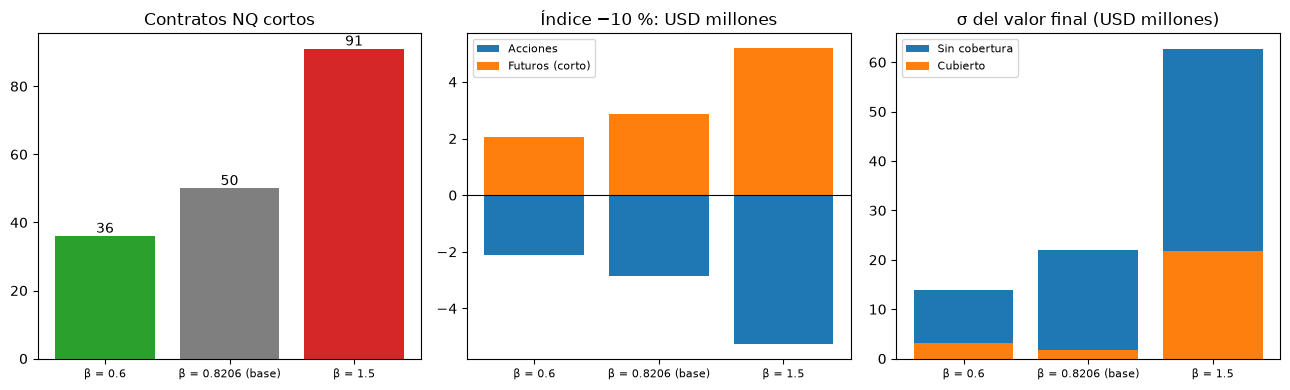

In [26]:
# 12.3 Gráfico: exposición sistemática, contratos y riesgo por beta
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
cols = sens.columns
ax[0].bar(cols, sens.loc["N (contratos)"], color=["tab:green", "tab:gray", "tab:red"])
ax[0].set_title("Contratos NQ cortos"); [ax[0].text(i, v, f"{int(v)}", ha="center", va="bottom") for i, v in enumerate(sens.loc["N (contratos)"])]
ax[1].bar(cols, sens.loc["Δ portafolio si índice −10 % (USD)"] / 1e6, color="tab:blue", label="Acciones")
ax[1].bar(cols, sens.loc["P&G corto si índice −10 % (USD)"] / 1e6, color="tab:orange", label="Futuros (corto)")
ax[1].axhline(0, color="black", lw=0.8); ax[1].set_title("Índice −10 %: USD millones"); ax[1].legend(fontsize=8)
ax[2].bar(cols, sens_mc.loc["σ sin cobertura"] / 1e6, color="tab:blue", label="Sin cobertura")
ax[2].bar(cols, sens_mc.loc["σ cubierto"] / 1e6, color="tab:orange", label="Cubierto")
ax[2].set_title("σ del valor final (USD millones)"); ax[2].legend(fontsize=8)
for a in ax: a.tick_params(axis="x", labelsize=8)
plt.tight_layout()
fig.savefig(RAIZ / "outputs" / "figures" / "sensibilidad_beta.png", dpi=150)
plt.show()

**Interpretación:**

- **Número de contratos:** crece junto con la beta: **36** contratos con β = 0.6, **50** con nuestra beta (0.8206) y **91** con β = 1.5.
    - Con β = 1.5 nuestra exposición al mercado sería de USD 52.5 M, **más que los USD 35 M que invertimos**. El portafolio se comportaría como si tuviéramos 1.5 veces su valor en el índice, y por eso la cobertura tiene que ser de ese tamaño.

- **Qué pasa si el índice cae 10 %?** Sin cobertura perderíamos USD 2.10 M con β = 0.6 y USD 5.25 M con β = 1.5.
    - En los tres casos el corto compensa casi toda la pérdida: lo que queda es apenas entre USD 19 mil y USD 57 mil, que viene del redondeo de contratos.
    - Cada tick pesa más con β alta: USD 180 por tick con β = 0.6 y USD 455 con β = 1.5.

- **Por qué una beta mayor exige una cobertura más intensa?** Cada contrato solo compensa el movimiento del índice 1 a 1. Si nuestro portafolio amplifica las caídas del mercado, necesitamos más contratos para igualar esa pérdida:
    - Con β = 1.5 necesitamos 2.5 veces los contratos del caso β = 0.6.
    - Eso significa más garantía inicial (USD 3.94 M frente a USD 1.56 M) y más dinero para reponer el margen (USD 58.3 M esperados frente a USD 23.1 M).
    - Los **llamados al margen son los mismos** en promedio (≈ 13.8 en los tres casos), porque las ganancias y pérdidas crecen igual que los márgenes. Lo que cambia es **cuánta plata** hay que reponer, no cuántas veces.

- **Qué tan bien funciona la cobertura con cada beta?** Con nuestra beta (0.82) la cobertura reduce el riesgo del valor final un 92 %. Con β = 0.6 lo reduce un 77 % y con β = 1.5 solo un 65 %.
    - La razón es la misma que vimos en el Punto 10: mantenemos el mismo número de contratos los 4 años, pero el portafolio no crece al mismo ritmo que la pérdida o ganancia de los futuros. Entre más lejos esté la beta de 1, más se descuadra la cobertura con el tiempo.
    - Con una beta alta sería todavía más importante **recalcular el número de contratos en cada roll-over**.

- **Conclusión:** la beta define el tamaño de la cobertura. Un portafolio más agresivo (β alta) necesita más contratos, más garantía y más caja para los llamados al margen, y aun así queda peor cubierto si no ajustamos los contratos. Uno más defensivo (β baja) necesita menos contratos y compromete menos capital.

## Conclusión general

- **Nuestro portafolio:** Máx. Sharpe con CSCO 40 %, ADI 45 % y PYPL 15 % (USD 35 M). Retorno esperado de 17.39 %, volatilidad de 25.63 % y beta mensual de 0.82.

- **Nuestra cobertura:** **50 contratos cortos E-mini Nasdaq-100 (NQ)** en CME, renovados cada trimestre. Necesitamos USD 2.17 M de garantía inicial y cubrimos el 99.35 % del riesgo de mercado.

- **¿Qué esperamos en 4 años? (10,000 simulaciones)**

| | Sin cobertura | Cubierto |
|---|---|---|
| Valor esperado con dividendos | USD 71.38 M | USD 43.64 M |
| Rentabilidad esperada al año (con dividendos) | ≈ 19.9 % | ≈ 5.8 % |
| Variación posible del valor final (σ) | USD 21.95 M | USD 1.81 M |
| Pérdida en un mes malo (VaR 95 %) | USD 2.88 M | USD 1.79 M |

- **Recomendación al gerente:**
    - Cubrirnos con futuros convierte el portafolio en una inversión de bajo riesgo que rinde cerca de la tasa libre de riesgo más los dividendos. A cambio renunciamos a la ganancia del mercado (≈ USD 28 M en promedio).
    - Esta estrategia tiene sentido si para la entidad es más importante **proteger el capital** que hacerlo crecer.
    - Si la aplicamos, necesitamos **tener caja disponible para los llamados al margen** (≈ 14 llamados y USD 32 M de reposición esperada en los 4 años) y, idealmente, **recalcular el número de contratos en cada roll-over**.
    - Si el objetivo es crecer, una cobertura parcial (menos contratos) nos dejaría aprovechar parte de la subida del mercado y limitar las caídas.